# dh single-locus RNAi model: all plots

Run the first three code cells once per session (matplotlib, settings, and the line that loads `dh_lib/dh_core.py`, which holds all the definitions). After that every cell can be run on its own, in any order; cells that need earlier data (histogram data, experiment files, traces) compute it themselves if it is not in memory. The sections with their own settings cell ("Panel settings") need that cell run once. Two parameter sets (coding, non-coding), six genotypes. Every run uses a new random seed. All settings (save folder, file formats, line widths, run numbers and lengths, trace length) are in the first code cell. Figures are saved as svg and png with transparent backgrounds.

ago1Δ: GAM = E_RW = E_NUC = 0. epe1-OE: D3 = 2.5.

**Simulator:** GillesPy2 (`pip install gillespy2`, plus a C++ compiler). The reactions are in the `REACTIONS` table.

In [17]:
%matplotlib inline

"""Single-locus Gillespie model of nuclear RNAi / heterochromatin at one S. pombe dh repeat."""
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

DIV = 150.0                 # generation time, min
MU  = np.log(2.0) / DIV     # dilution by growth, min^-1
N   = 20                    # nucleosomes in one dh locus

# ============================== USER SETTINGS ==============================
SAVE_DIR         = Path("/Users/sumanth/Library/CloudStorage/Box-Box/Manuscript_RNAi/Manuscript_10152026/simulations")   # figure folder
SAVE_FORMATS     = ("svg", "png")     # file types
SAVE_DPI         = 250                # png resolution
TRACE_LW         = 0.6                # trace width in multi-panel figures
TRACE_LW_PUB     = 1.0                # trace width in the panel figures (section 5)
HIST_LW          = 0.8                # histogram outline width
NULLCLINE_LW     = 2.0                # nullcline width
TRACE_RASTERIZED = False              # False = vector traces in the svg
TGENS            = 100                # generations shown
TRACE_BURNIN     = 20                 # generations simulated first and discarded (burn-in)
SHOW_EXPERIMENT  = True               # overlay the experimental distributions
EXP_DH_DIR       = Path("/Volumes/SUMANTH/Manuscript/dh distributions")     # dh csv folder
EXP_URA4_DIR     = Path("/Volumes/SUMANTH/Manuscript/ura4 distributions")   # ura4 csv folder
NRUNS            = 500                # histograms: runs per genotype and set
RUN_GENS         = 40                 # histograms: generations per run (last value kept)
XMAX_R           = {"coding": 40, "non-coding": 50}   # last R-histogram bar collects values >= this
NLOCI_SUM        = {"coding": 1, "non-coding": 10}   # loci summed per run (histograms and traces)
EXP_OWN_YSCALE   = True               # section 4: experiment histogram has its own y scale
# ============================================================================
SAVE_DIR.mkdir(parents=True, exist_ok=True); OUTDIR = SAVE_DIR
# live text in svg
plt.rcParams["svg.fonttype"] = "none"

# ---- parameters (earlier values from model_parameters.xlsx commented out) ----
# SHARED = dict(K1=0.3, R1=3.0, D1=0.063, D2=0.00578, D3=0.05, E_RW=2.1478, E_NUC=0.01419)
# PARAM_SETS = {
#     "coding":     dict(T=1.014705, GAM=0.172976, KS=23.32193, NS=10, NU=2.6e-5),
#     "non-coding": dict(T=0.13,     GAM=1.0,      KS=1.0,      NS=10, NU=1e-3),
# }
SHARED = dict(K1=0.3, R1=3.0, D1=0.06, D2=0.006, D3=0.05, E_RW=2, E_NUC=0.01)
PARAM_SETS = {
    "coding":     dict(T=1, GAM=0.2, KS=30, NS=10, NU=2e-5),
    "non-coding": dict(T=0.15,     GAM=1.0,      KS=1.0,      NS=10, NU=1e-3),
}

# ---- experimental RNA-FISH files (section 1b) ----
# set -> {genotype key: (csv file, spot-count column)}
EXP_FILES = {
    "non-coding": {   # dh
        "WT":        ("WTdh_ch0_ch1_spots_per_cell.csv",       "ch0_spots"),
        "clr4_del":  ("clr4D_dh_ch0_ch1_spots_per_cell.csv",   "ch0_spots"),
        "ago1_del":  ("ago1Ddh_ch0_ch1_spots_per_cell.csv",    "ch0_spots"),
        "clr4_W31G": ("clr4W31Gdh_ch0_ch1_spots_per_cell.csv", "ch0_spots"),
        "epe1_del":  ("dh_epe1D_cell_summary_0.csv",           "spot_count"),
        "epe1_OE":   ("dh_epe1OE_ch0_ch1_spots_per_cell.csv",  "ch0_spots"),
    },
    "coding": {       # ura4 (no epe1-OE)
        "WT":        ("ura4_WT_cell_summary_1.csv",            "spot_count"),
        "clr4_del":  ("ura4_clr4D_combined_df_channel2.csv",   "spot_count"),
        "ago1_del":  ("ura4_ago1D_combined_df_channel2.csv",   "spot_count"),
        "clr4_W31G": ("ura4_W31G_cell_summary_1.csv",          "spot_count"),
        "epe1_del":  ("ura4_epe1D_cell_summary_1.csv",         "spot_count"),
    },
}
EXP_DIRS = {"non-coding": EXP_DH_DIR, "coding": EXP_URA4_DIR}

# ---- definitions: model, simulation, plot helpers (file dh_lib/dh_core.py, next to this notebook) ----
# Run once per session, and again after changing PARAM_SETS / SHARED above.
%run -i dh_core.py

<Figure size 640x480 with 0 Axes>

## 1. Histogram data: many short runs, last value kept

In [2]:
# ---- histogram data: many short runs, last value of each ----
res = make_res()

coding (sum of 1 locus/loci), 500 runs x 40 generations
  WT                  RNA   0.64   siRNA    47.6   methylation fraction  0.77
  $\it{clr4}\Delta$   RNA  15.50   siRNA     0.0   methylation fraction  0.00
  $\it{ago1}\Delta$   RNA  15.33   siRNA     0.0   methylation fraction  0.00
  $\it{clr4}$-W31G    RNA   3.54   siRNA   190.5   methylation fraction  0.35
  $\it{epe1}\Delta$   RNA  10.39   siRNA     5.3   methylation fraction  0.31
  $\it{epe1}$-OE      RNA   3.15   siRNA   224.0   methylation fraction  0.38
non-coding (sum of 10 locus/loci), 500 runs x 40 generations
  WT                  RNA   0.77   siRNA   448.0   methylation fraction  0.46
  $\it{clr4}\Delta$   RNA  22.74   siRNA     2.3   methylation fraction  0.00
  $\it{ago1}\Delta$   RNA  23.07   siRNA     2.1   methylation fraction  0.00
  $\it{clr4}$-W31G    RNA   7.49   siRNA   825.3   methylation fraction  0.12
  $\it{epe1}\Delta$   RNA   2.05   siRNA   106.3   methylation fraction  0.66
  $\it{epe1}$-OE      RNA

## 1b. Experimental RNA-FISH data
Spot counts per cell for non-coding (dh) and coding (ura4), overlaid on the simulated R histograms. Set the folders in the settings block.

In [3]:
# ---- experimental RNA-FISH spot counts per cell (files and folders: settings cell) ----
exp_data = load_exp_data()

non-coding  WT                 WTdh_ch0_ch1_spots_per_cell.csv               n =  565 cells, mean =  0.84
non-coding  $\it{clr4}\Delta$  clr4D_dh_ch0_ch1_spots_per_cell.csv           n =  932 cells, mean = 22.81
non-coding  $\it{ago1}\Delta$  ago1Ddh_ch0_ch1_spots_per_cell.csv            n =  425 cells, mean = 19.66
non-coding  $\it{clr4}$-W31G   clr4W31Gdh_ch0_ch1_spots_per_cell.csv         n =  792 cells, mean =  6.14
non-coding  $\it{epe1}\Delta$  dh_epe1D_cell_summary_0.csv                   n =  859 cells, mean =  1.61
non-coding  $\it{epe1}$-OE     dh_epe1OE_ch0_ch1_spots_per_cell.csv          n = 1004 cells, mean = 12.59
coding      WT                 ura4_WT_cell_summary_1.csv                    n = 1289 cells, mean =  0.28
coding      $\it{clr4}\Delta$  ura4_clr4D_combined_df_channel2.csv           n =  279 cells, mean = 15.50
coding      $\it{ago1}\Delta$  ura4_ago1D_combined_df_channel2.csv           n =  552 cells, mean = 13.72
coding      $\it{clr4}$-W31G   ura4_W31G_cell_

## 2. Traces and histograms for each genotype
One figure per genotype: R, S and methylation-fraction traces with their histograms, for the coding and non-coding sets. The traces are stored in `trace_store` for the panel sections; the burn-in is already removed.

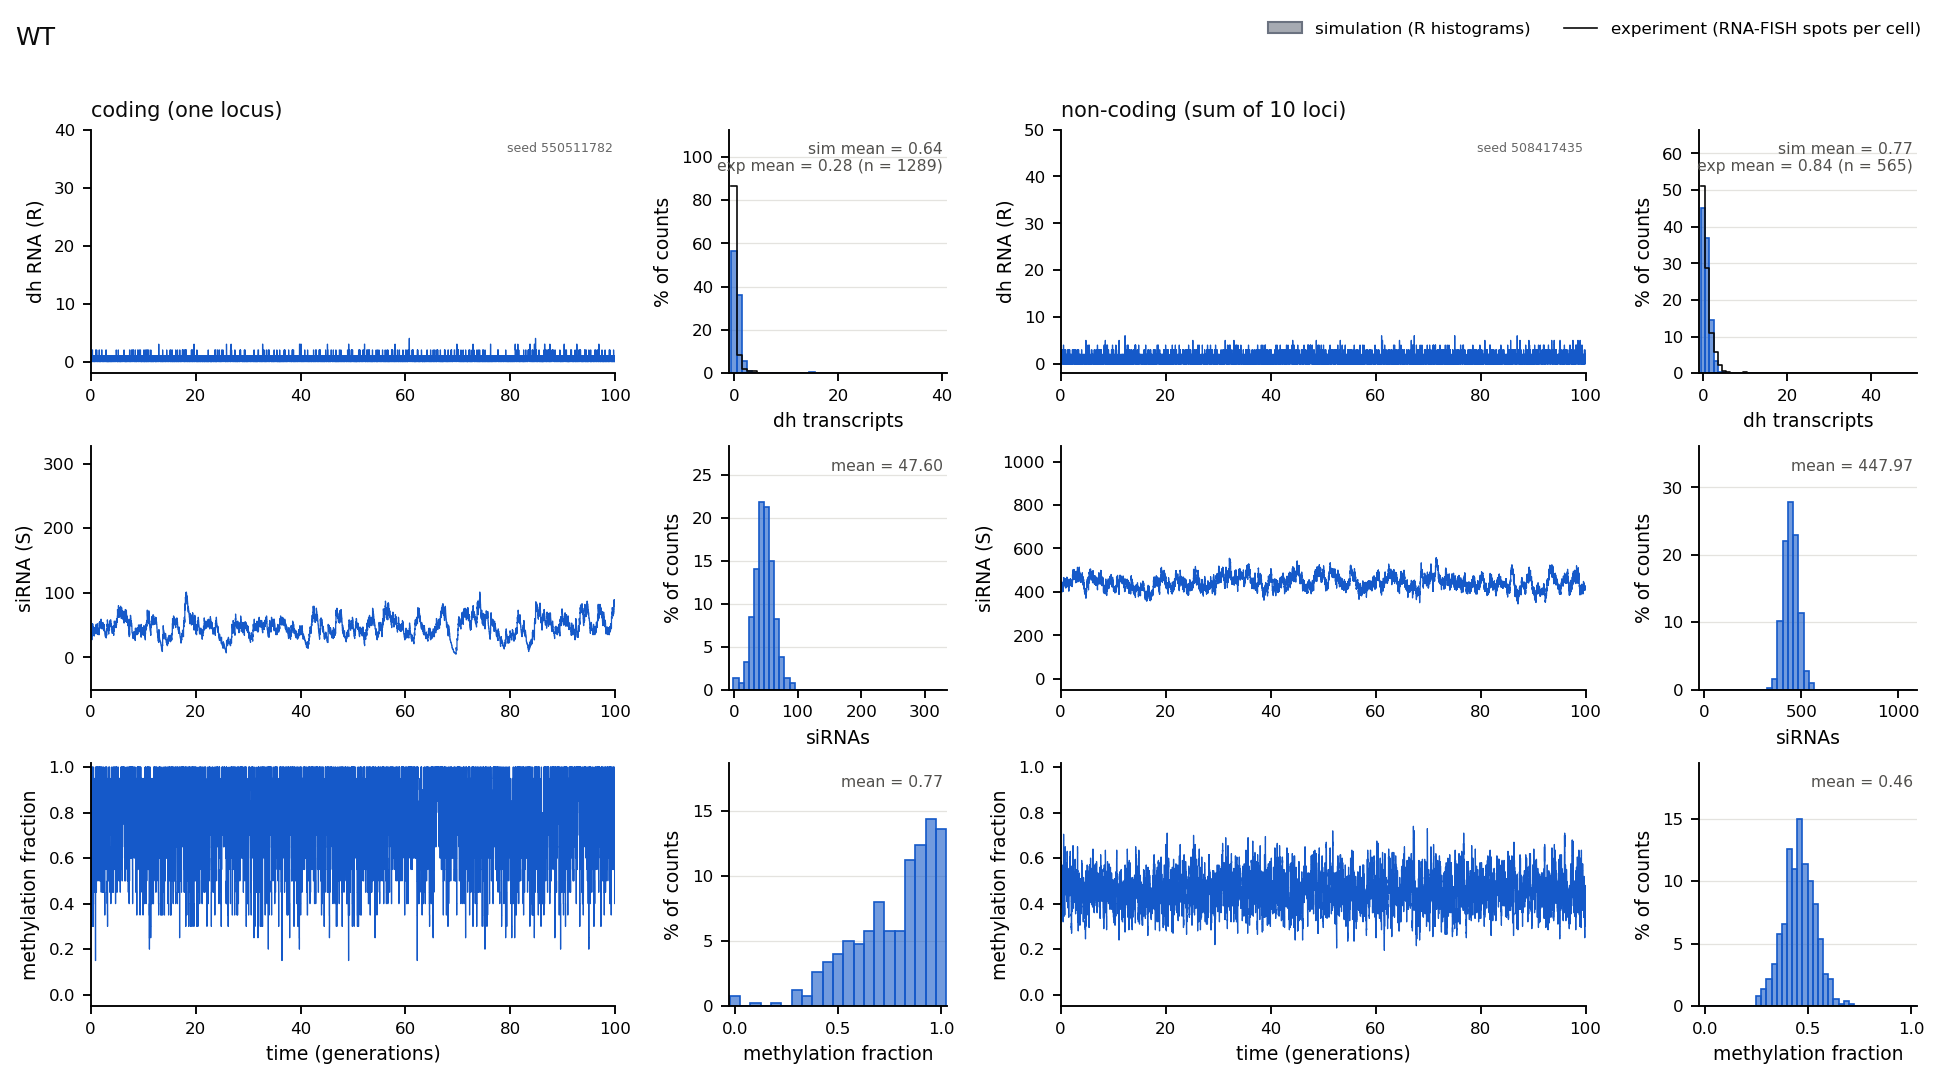

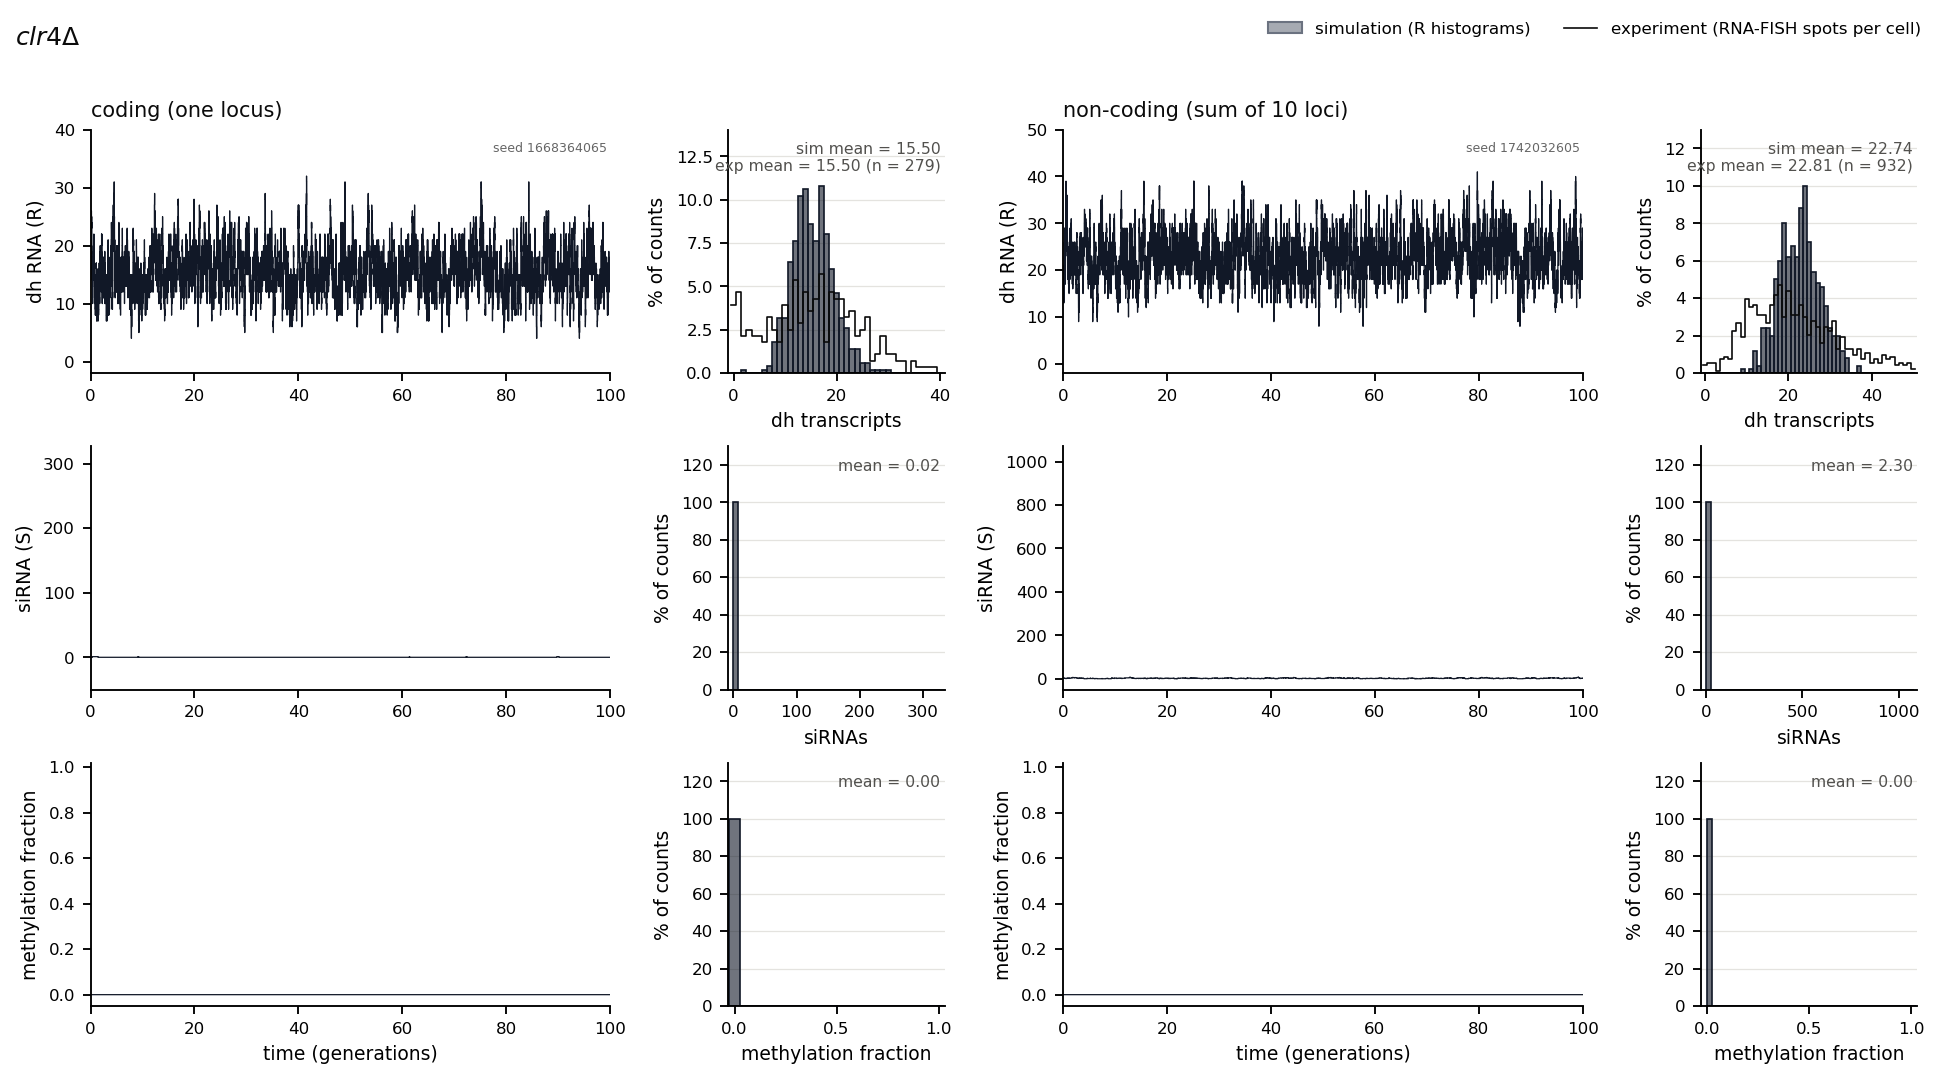

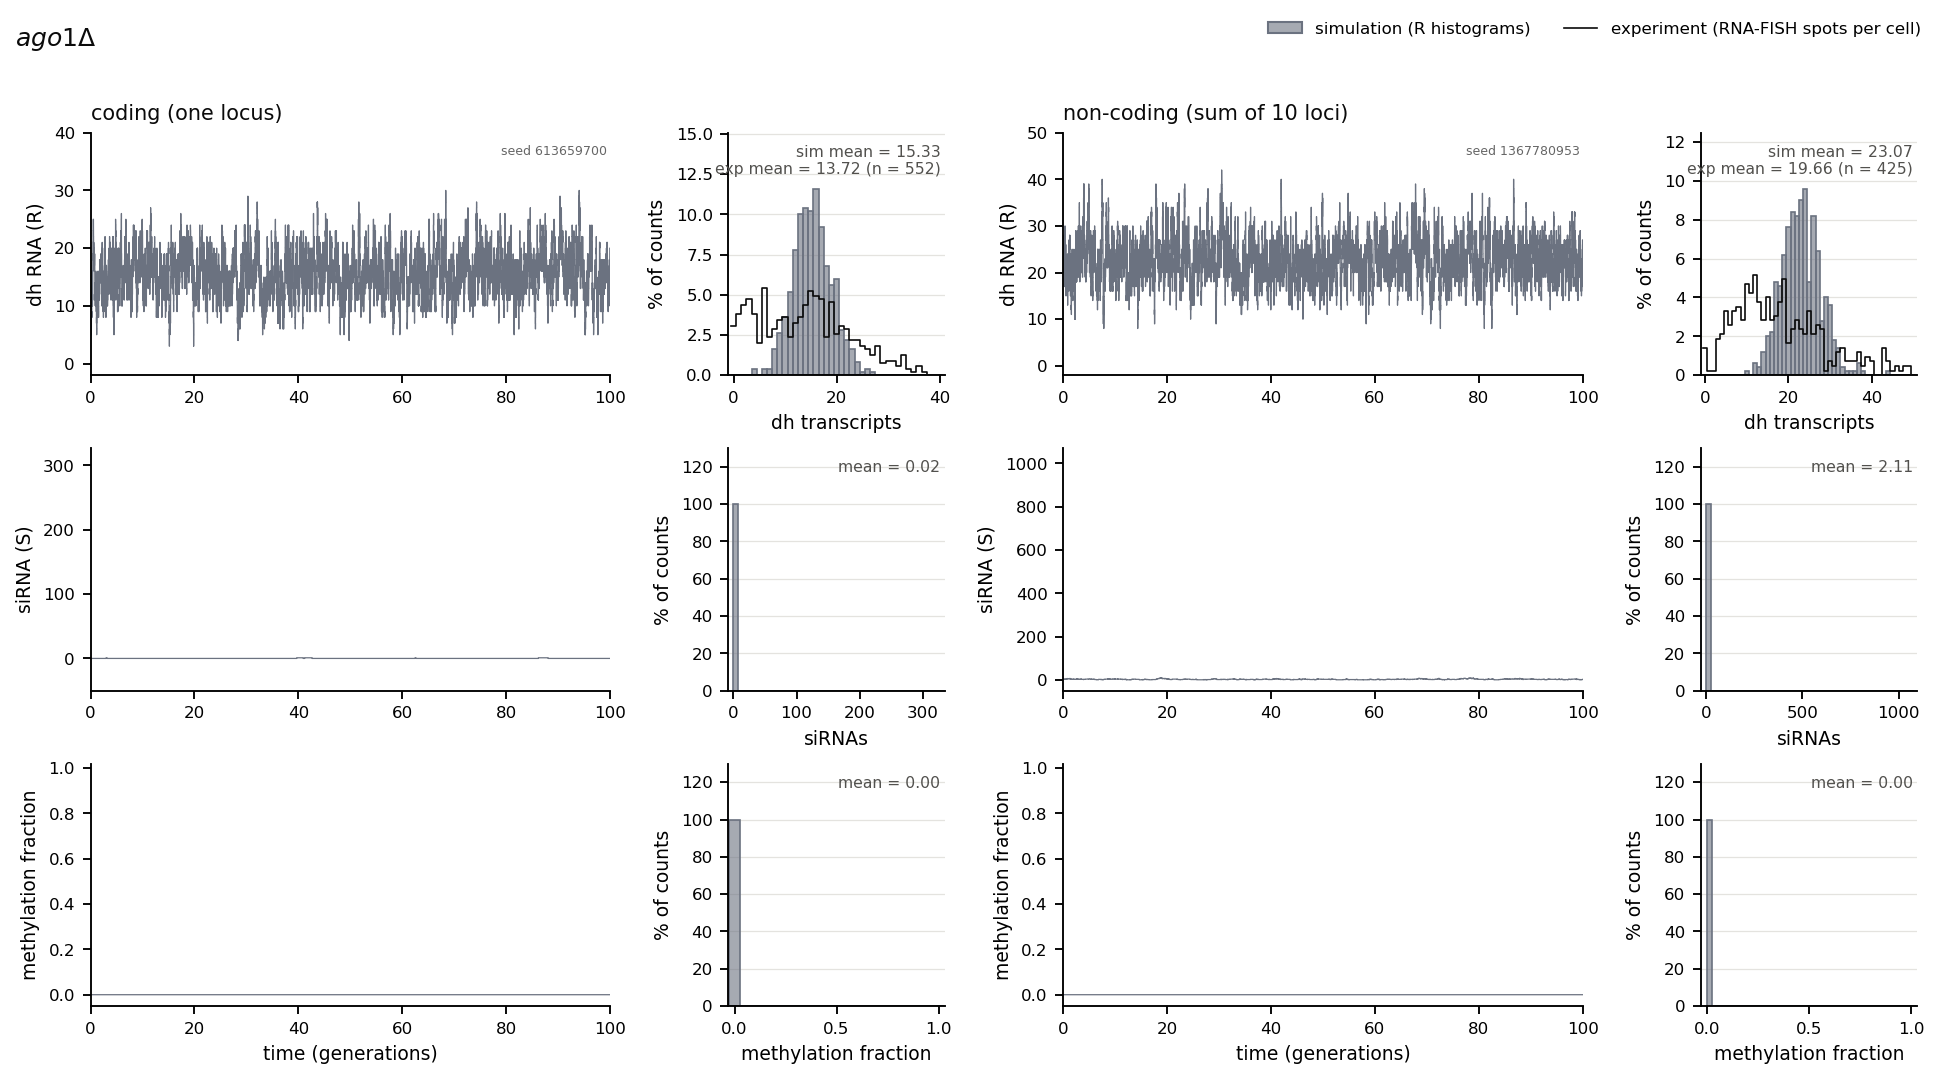

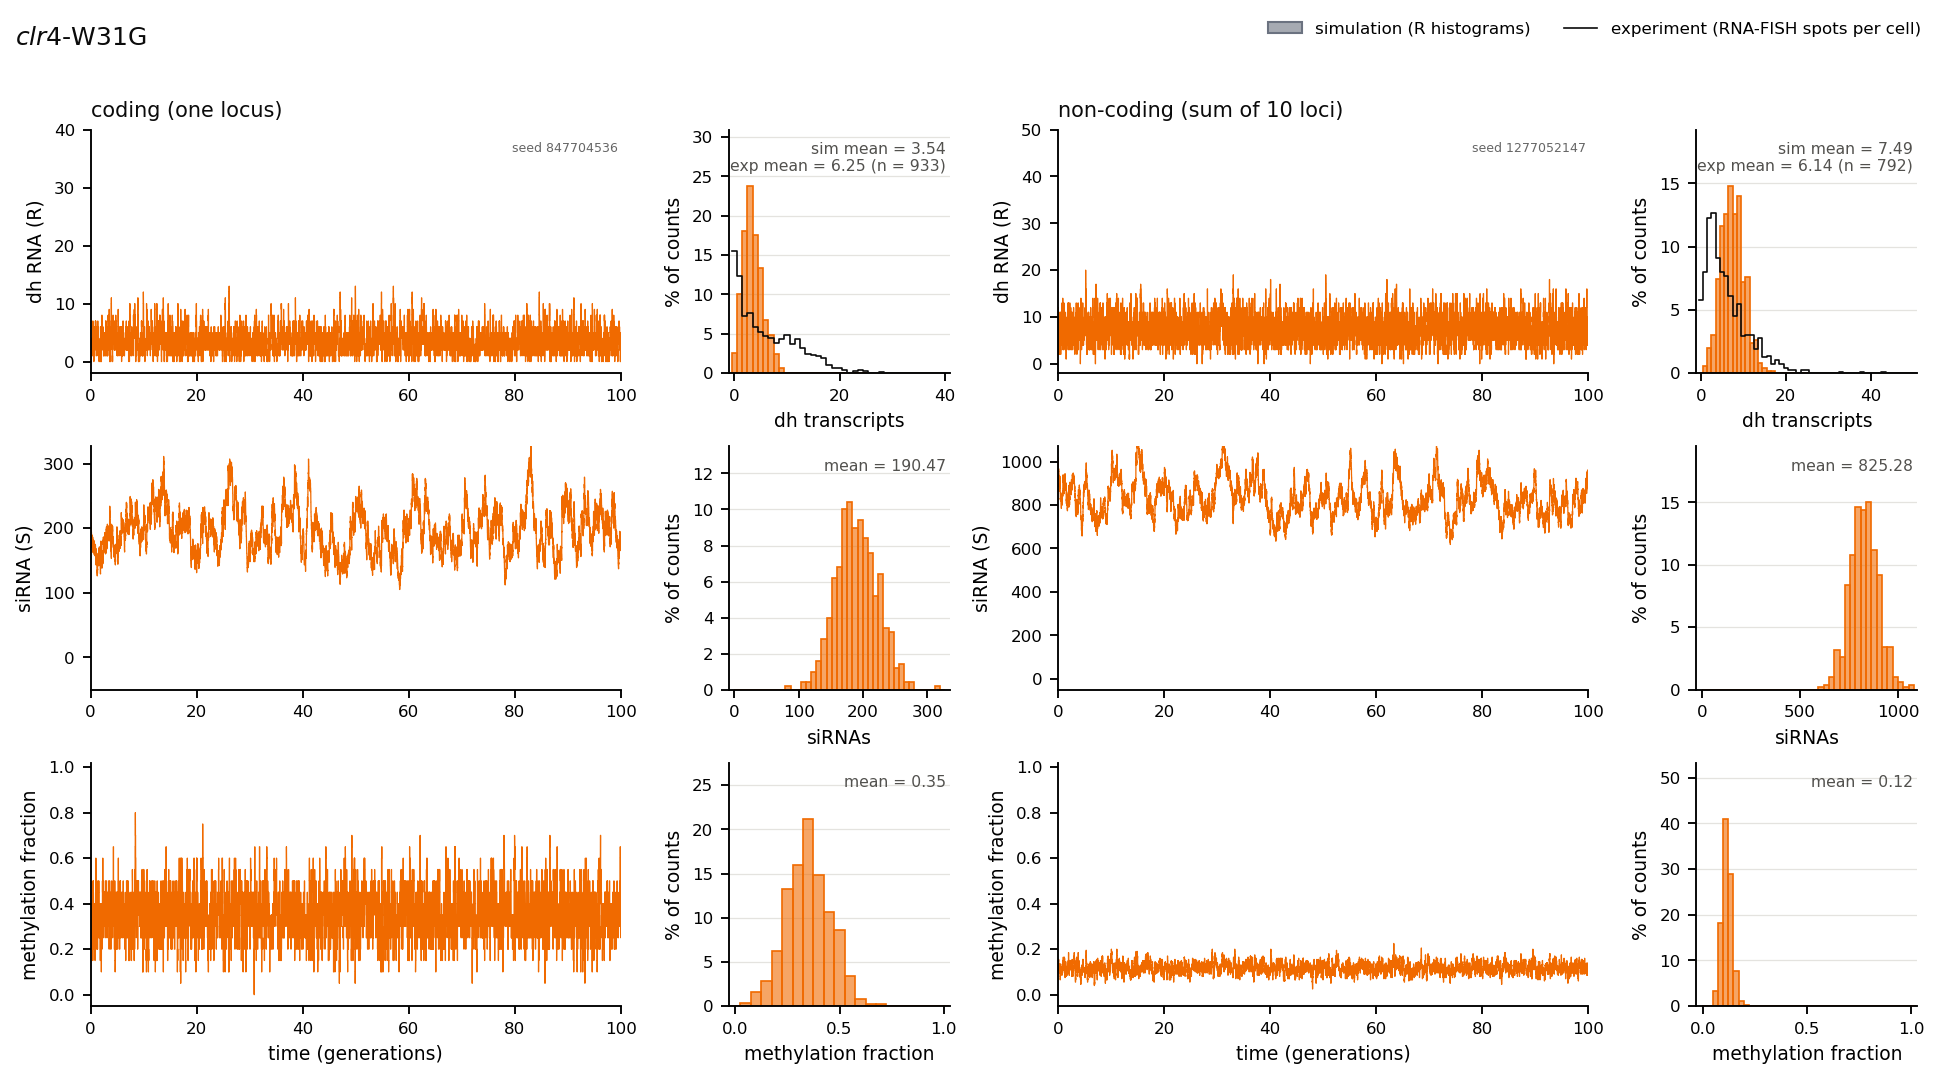

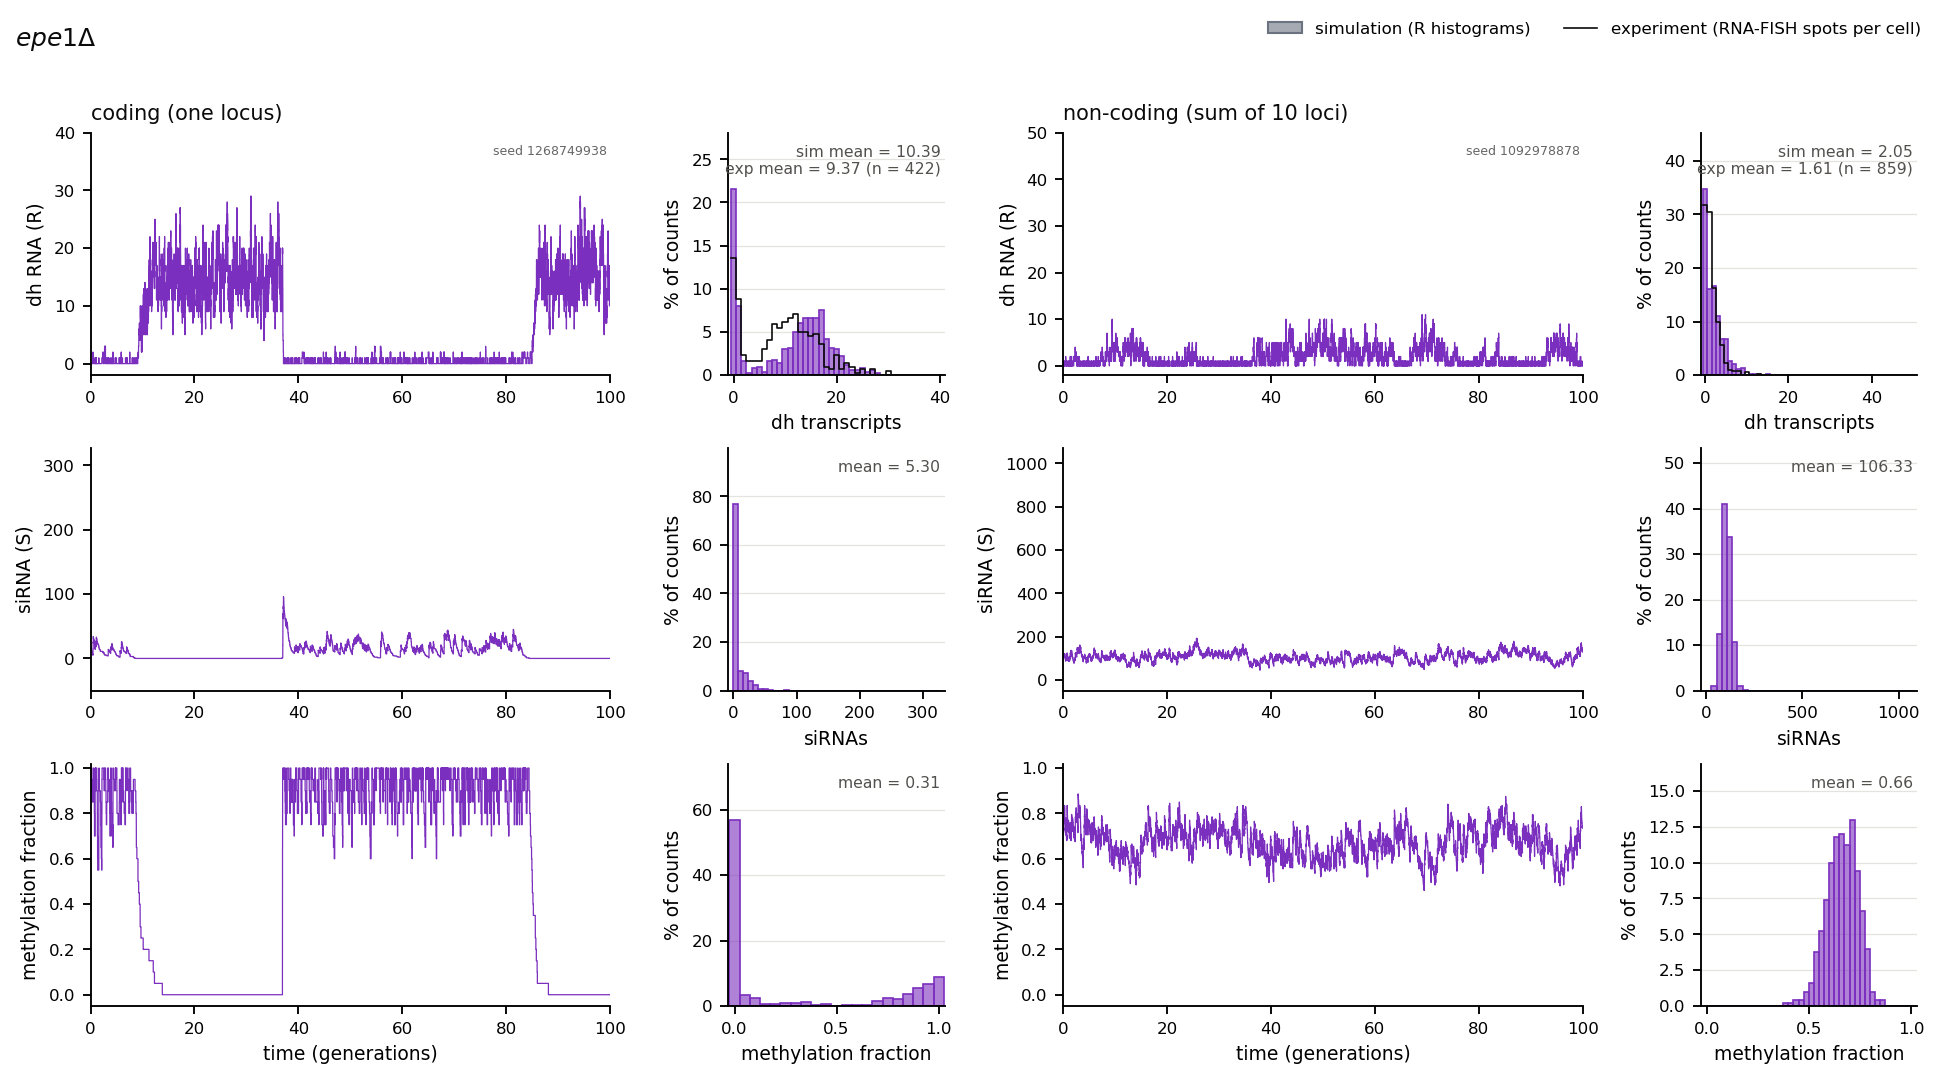

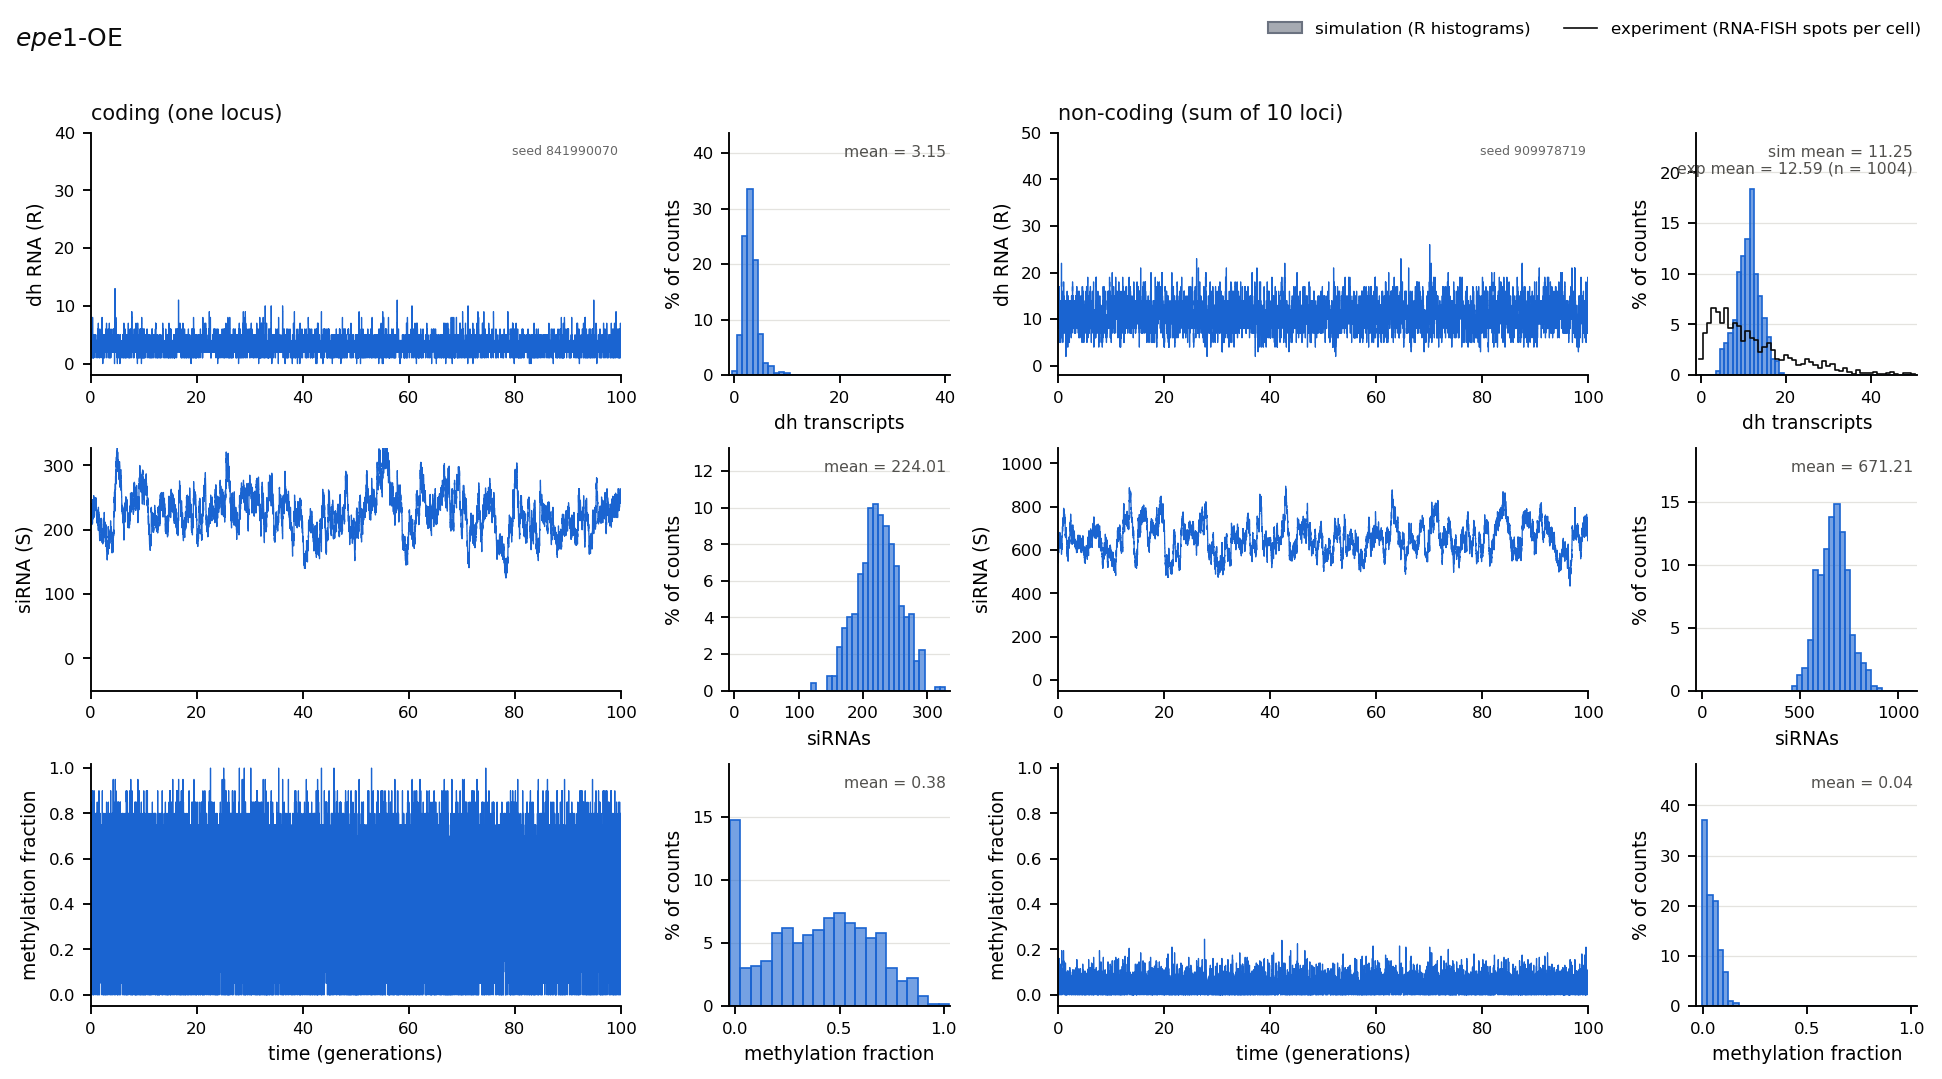

In [4]:
# ---- one figure per genotype: R, S, M traces and histograms (coding | non-coding) ----
# Non-coding = sum of NLOCI_SUM loci (R, S summed; methylation fraction = mean over the loci).
# data from sections 1 and 1b are computed here if they are not in memory yet
if "res" not in globals(): res = make_res()
if "exp_data" not in globals(): exp_data = load_exp_data()
TNREC = (TGENS + TRACE_BURNIN) * 160                 # records per simulated trace
tg = np.arange(TGENS * 160) / 160                    # time axis of the part shown
SLUG = [GENO_KEY[g[0]] for g in GENOS]               # file-name tags

def xmax_for(q, sname):
    if q == "R": return XMAX_R[sname]
    if q == "S":
        allv = np.concatenate([res["S"][(sname, g[0])] for g in GENOS])
        return float(np.ceil(allv.max()))                 # full range: nothing is clipped
    return N * NLOCI_SUM[sname]                      # M: full range 0 ... N x loci

def binned(T, xm, bw):
    """% of counts per bin (edges at half-integers). Values above the last bin are not drawn."""
    edges = -0.5 + bw * np.arange(int(np.ceil((xm + 0.5) / bw)) + 1)
    f = 100.0 * np.histogram(T, bins=edges)[0] / len(T)
    return edges, f

def overlay_experiment(ax, sname, lab, xm, bw, edges, f, T):
    """Experimental distribution as a black outline. Returns its tallest bar and the mean label."""
    E = exp_data.get((sname, lab))
    if E is None: return 0.0, "mean = %.2f" % T.mean()
    _, fe = binned(E, xm, bw)
    ax.step(edges, np.append(fe, fe[-1]), where="post", color=INK, lw=HIST_LW, zorder=4)
    return fe.max(), "sim mean = %.2f\nexp mean = %.2f (n = %d)" % (T.mean(), E.mean(), len(E))

def exp_legend(fig):
    """One legend per figure: bars = simulation, outline = experiment."""
    if exp_data:
        fig.legend(handles=[Patch(facecolor=mcolors.to_rgba("#6b7280", 0.6), edgecolor="#6b7280", label="simulation (R histograms)"),
                            Line2D([], [], color=INK, lw=HIST_LW, label="experiment (RNA-FISH spots per cell)")],
                   loc="upper right", ncol=2, frameon=False, fontsize=8, bbox_to_anchor=(0.995, 0.998))

QLAB = {"R": ("dh RNA (R)", "dh transcripts"), "S": ("siRNA (S)", "siRNAs"),
        "M": ("methylation fraction", "methylation fraction")}

trace_store = {}                                     # (set, genotype) -> {"R", "S", "M", "seed"}
for gi, geno in enumerate(GENOS):
    lab, *_, col = geno
    with plt.rc_context(RC):
        fig, axes = plt.subplots(3, 4, figsize=(13, 7.2), gridspec_kw={"width_ratios": [2.4, 1, 2.4, 1]})
        for c, sname in enumerate(PARAM_SETS):
            nl = NLOCI_SUM[sname]
            R, M, S, seed = run_locus(sname, geno, TGENS + TRACE_BURNIN, TNREC) if nl == 1 else \
                            run_loci(sname, geno, TGENS + TRACE_BURNIN, TNREC, nl)
            R, M, S = (cut_burnin(v, TGENS + TRACE_BURNIN) for v in (R, M, S))      # drop the burn-in
            traces = {"R": R, "S": S, "M": M / nl}                 # M: fraction (0-1)
            trace_store[(sname, lab)] = dict(traces, seed=seed)     # for the panel cells
            for r, q in enumerate("RSM"):
                xm = xmax_for(q, sname)
                # trace
                ax = axes[r, 2 * c]
                draw_trace(ax, tg[:len(traces[q])], traces[q], col)
                style_trace_axes(ax, xlim=(0, TGENS), ylim=(-0.05, 1.02) if q == "M" else ((-2, xm) if q == "R" else (-50, xm)), ylabel=QLAB[q][0])
                if r == 0: ax.set_title(sname + (" (sum of %d loci)" % nl if nl > 1 else " (one locus)"),
                                        loc="left", fontsize=10, color=INK)
                if r == 0: ax.text(0.995, 0.95, "seed %d" % seed, transform=ax.transAxes, va="top",
                                   ha="right", fontsize=6, color="#666666")
                if r == 2: ax.set_xlabel("time (generations)")
                # histogram of the pooled runs
                ax = axes[r, 2 * c + 1]
                T = res[q][(sname, lab)]                           # R, S sums; M = methylated nucleosome count
                bw = max(1, int(round(xm / 40))); edges, f = binned(T, xm, bw)
                s = xm if q == "M" else 1                          # M is plotted as a fraction
                ctr = (edges[:-1] + edges[1:]) / 2 / s; wid = bw / s; mean = T.mean() / s
                ax.set_xlim(-0.03, 1.03) if q == "M" else ax.set_xlim(-bw, xm + bw)
                ax.bar(ctr, f, width=wid, facecolor=mcolors.to_rgba(col, 0.6), edgecolor=col, linewidth=HIST_LW)
                emax, txt = overlay_experiment(ax, sname, lab, xm, bw, edges, f, T) if q == "R" else (0.0, "mean = %.2f" % mean)
                ax.set_ylim(0, max(f.max(), emax, 1e-9) * 1.3)
                ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
                ax.text(0.98, 0.95, txt, transform=ax.transAxes, va="top", ha="right",
                        fontsize=7.5, color=INK2)
                ax.set_ylabel("% of counts"); ax.set_xlabel(QLAB[q][1])
        fig.suptitle(lab, x=0.01, ha="left", fontsize=12, color=INK); exp_legend(fig)
        fig.tight_layout(h_pad=0.8, w_pad=1.2, rect=(0, 0, 1, 0.97))
        save_fig(fig, "dh_panel_%d_%s" % (gi + 1, SLUG[gi]))
        plt.show()

## 3. Nullclines in the (S, M) plane
Mean-field of the same reactions, one figure per set. Fixed points: filled = stable, open = unstable.

coding   fixed points (per locus):   S        M       R     stability
   WT                      23.1   0.819   0.345   stable
   $\it{clr4}\Delta$     0.0291   0.000  15.470   stable
   $\it{ago1}\Delta$     0.0291   0.000  15.470   stable
   $\it{clr4}$-W31G         181   0.341   3.292   stable
   $\it{epe1}\Delta$       12.9   0.968   0.236   stable
   $\it{epe1}$-OE        0.0293   0.000  15.470   stable
   $\it{epe1}$-OE          1.78   0.011  15.441   unstable
   $\it{epe1}$-OE           148   0.389   2.433   stable


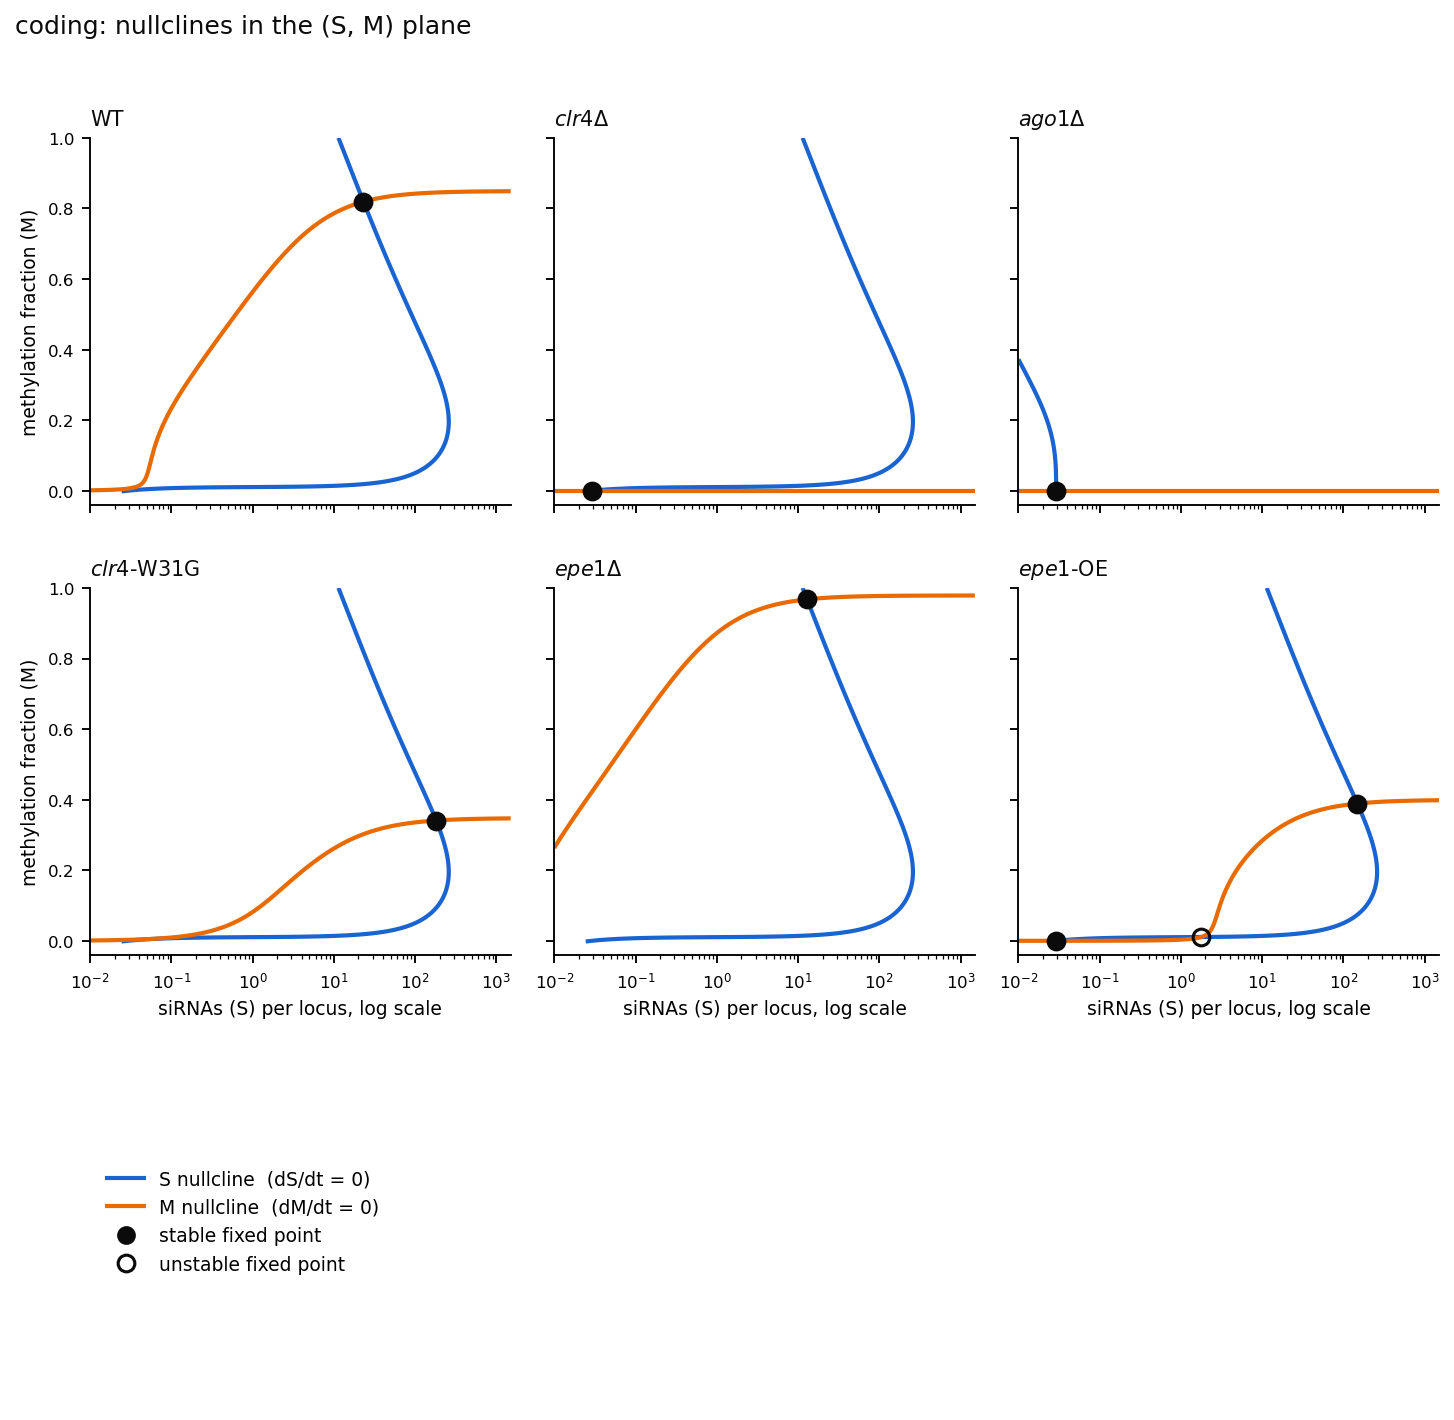

non-coding   fixed points (per locus):   S        M       R     stability
   WT                      23.8   0.484   0.055   stable
   $\it{clr4}\Delta$      0.215   0.000   2.286   stable
   $\it{ago1}\Delta$      0.215   0.000   2.286   stable
   $\it{clr4}$-W31G        85.6   0.121   0.760   stable
   $\it{epe1}\Delta$       7.21   0.769   0.011   stable
   $\it{epe1}$-OE          64.1   0.056   1.236   stable


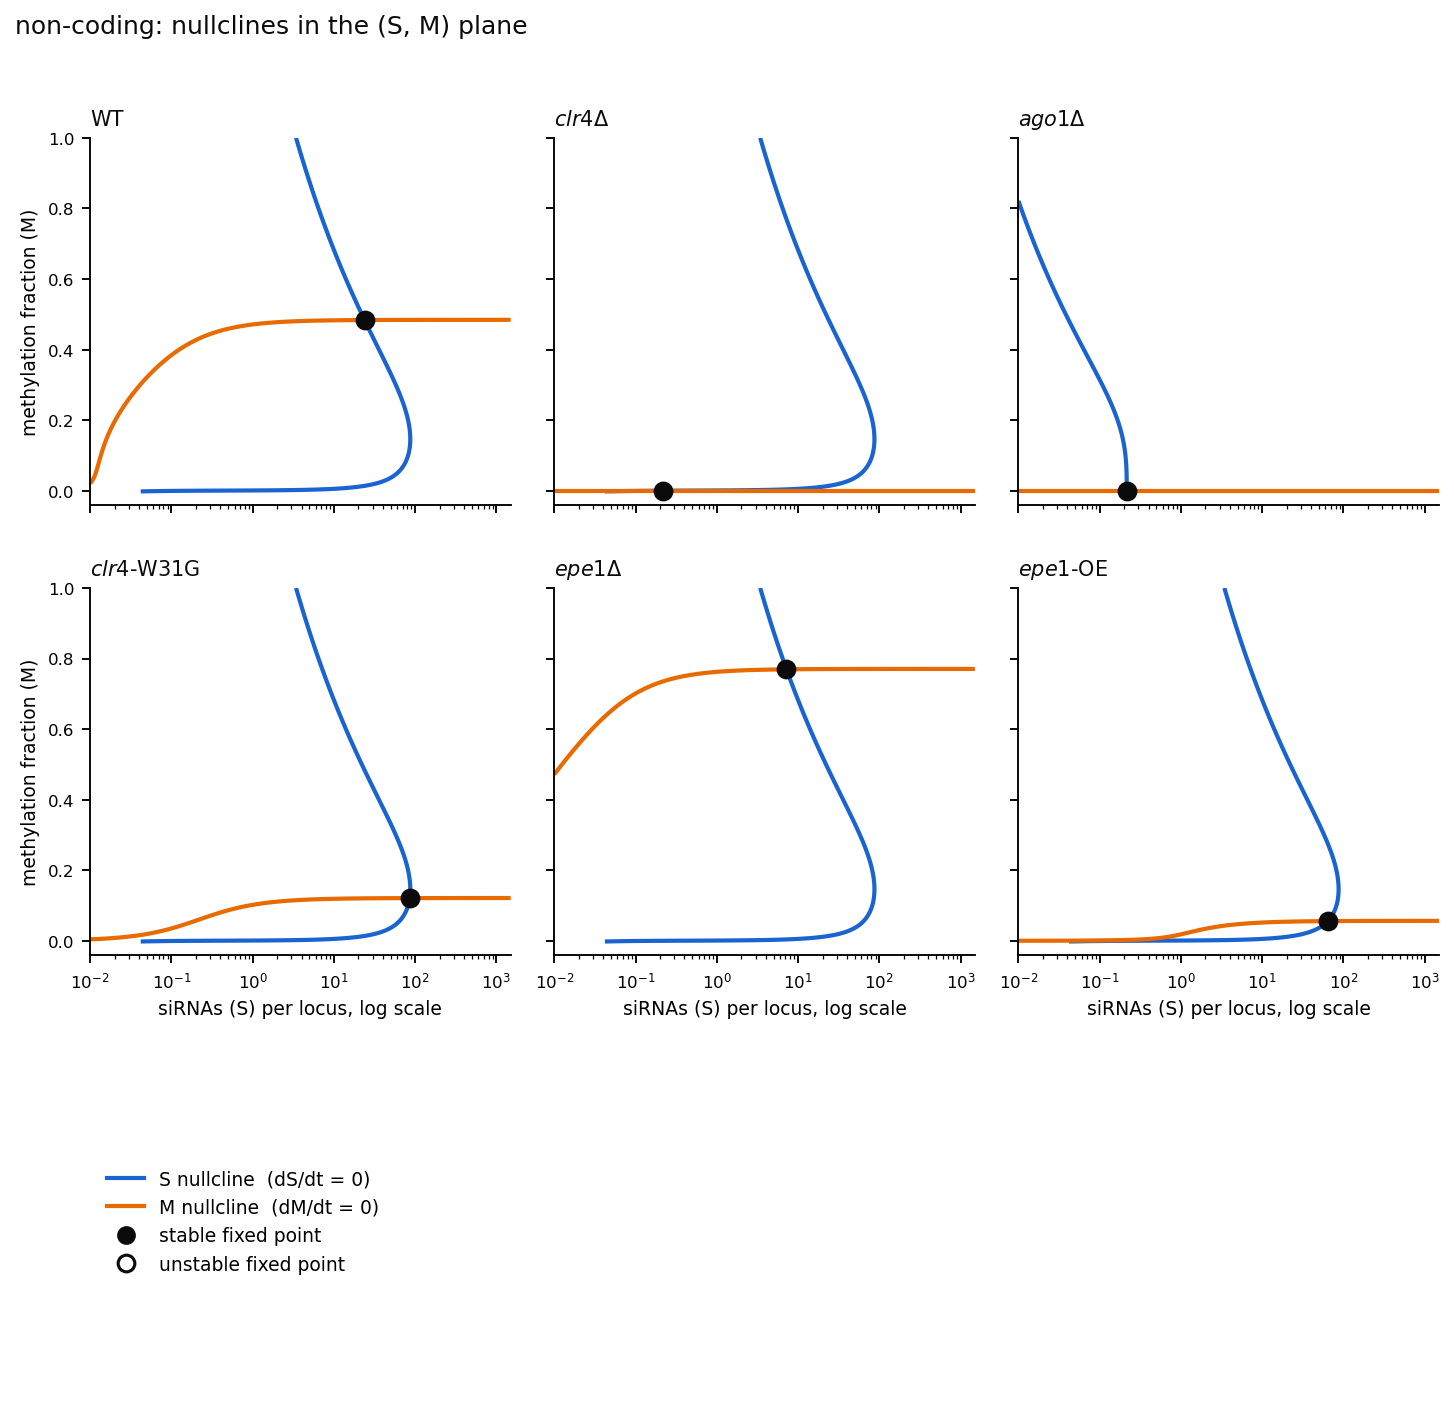

In [31]:
# ---- nullclines in the (S, M) plane: one figure per parameter set ----
# Mean-field per locus (M = m/N, HS = S/(kS+S)); on each nullcline R is at its steady state R*(S, M):
#   dR/dt = T/(1+(M/k1)^r1) - (d1 + g*M*HS + nu + mu)*R
#   dS/dt = (NS*g*M*HS + nu)*R - (d2 + mu)*S
#   dM/dt = R*HS*(e_rw*M + e_nuc)*(1-M) - (d3 + mu)*M
# Fixed points = nullcline crossings; stability from the eigenvalues of the 3-variable system.
from scipy.optimize import fsolve
np.seterr(all="ignore")                              # ignore overflow warnings from fsolve

def mean_field(sname, geno):
    P = {**SHARED, **PARAM_SETS[sname]}; _, gs, uw, un, d3, _ = geno
    p = dict(T=P["T"], k1=P["K1"], r1=P["R1"], d1=P["D1"], g=P["GAM"] * gs, kS=P["KS"], NS=P["NS"],
             d2=P["D2"], nu=P["NU"], e_rw=P["E_RW"] * uw, e_nuc=P["E_NUC"] * un, d3=d3)
    def rates(R, S, M):                                # (dR/dt, dS/dt, dM/dt)
        HS = S / (p["kS"] + S)
        return (p["T"] / (1 + (M / p["k1"]) ** p["r1"]) - (p["d1"] + p["g"] * M * HS + p["nu"] + MU) * R,
                (p["NS"] * p["g"] * M * HS + p["nu"]) * R - (p["d2"] + MU) * S,
                R * HS * (p["e_rw"] * M + p["e_nuc"]) * (1 - M) - (p["d3"] + MU) * M)
    def Rstar(S, M):
        HS = S / (p["kS"] + S)
        return p["T"] / (1 + (M / p["k1"]) ** p["r1"]) / (p["d1"] + p["g"] * M * HS + p["nu"] + MU)
    FS = lambda S, M: rates(Rstar(S, M), S, M)[1]
    FM = lambda S, M: rates(Rstar(S, M), S, M)[2]
    full = lambda x: np.array(rates(*x))               # full 3-variable system, for stability
    return p, Rstar, FS, FM, full

def fixed_points(p, Rstar, FS, FM, full):
    # solve in (log S, M) on relative residuals
    def resid(v):
        S, M = np.exp(v[0]), v[1]
        return [FS(S, M) / ((p["d2"] + MU) * S), FM(S, M) / (p["d3"] + MU)]
    pts = []
    for lS in np.linspace(np.log(1e-3), np.log(3e3), 22):
        for M0 in np.linspace(0.0, 0.99, 22):
            sol, info, ier, _ = fsolve(resid, [lS, M0], full_output=True)
            if ier == 1 and np.hypot(*resid(sol)) < 1e-7 and -1e-6 < sol[1] < 1 and abs(sol[0]) < 12 \
               and not any(abs(sol[0] - a) < 1e-3 and abs(sol[1] - b) < 1e-3 for a, b in pts):
                pts.append((sol[0], sol[1]))
    out = []
    for lS, M1 in sorted(pts):
        S1 = np.exp(lS); x0 = np.array([Rstar(S1, M1), S1, M1]); J = np.zeros((3, 3))
        for j in range(3):
            d = np.zeros(3); d[j] = 1e-6 * max(1.0, abs(x0[j]))
            J[:, j] = (full(x0 + d) - full(x0 - d)) / (2 * d[j])
        out.append((S1, max(M1, 0.0), Rstar(S1, M1), np.linalg.eigvals(J).real.max() < 0))
    return out

NC_COL_S, NC_COL_M = "#1a64d1", "#e86a00"
Sg = np.logspace(-2, np.log10(1500), 700); Mg = np.linspace(-0.002, 1.0, 700)       # starts below 0 so a nullcline on M = 0 is drawn
SS, MM = np.meshgrid(Sg, Mg)
NCOLS = 3                                                # subplots per row
NROWS = -(-(len(GENOS) + 1) // NCOLS)                    # genotypes + 1 slot for the legend
for sname in PARAM_SETS:
    with plt.rc_context(RC):
        fig, axes = plt.subplots(NROWS, NCOLS, figsize=(13 * NCOLS / 4, 3.2 * NROWS), sharex=True, sharey=True)
        print(sname, "  fixed points (per locus):   S        M       R     stability")
        for k, geno in enumerate(GENOS):
            ax = axes.flat[k]
            p, Rstar, FS, FM, full = mean_field(sname, geno)
            ax.contour(SS, MM, FS(SS, MM), levels=[0], colors=[NC_COL_S], linewidths=NULLCLINE_LW)
            ax.contour(SS, MM, FM(SS, MM), levels=[0], colors=[NC_COL_M], linewidths=NULLCLINE_LW)
            for S1, M1, R1, st in fixed_points(p, Rstar, FS, FM, full):
                ax.plot(S1, M1, "o", ms=8, mfc=INK if st else "none", mec=INK, mew=1.5, zorder=5, clip_on=False)
                print("   %-18s %9.3g  %6.3f  %6.3f   %s" % (geno[0], S1, M1, R1, "stable" if st else "unstable"))
            ax.set_xscale("log"); ax.set_xlim(1e-2, 1500); ax.set_ylim(-0.04, 1.0)
            ax.set_title(geno[0], loc="left", fontsize=10, color=INK)
            if k % NCOLS == 0: ax.set_ylabel("methylation fraction (M)")
            if k + NCOLS >= len(GENOS):                          # bottom row: show the x axis
                ax.tick_params(labelbottom=True); ax.set_xlabel("siRNAs (S) per locus, log scale")
        for ax in axes.flat[len(GENOS):]: ax.axis("off")
        lg = axes.flat[len(GENOS)]
        lg.plot([], [], color=NC_COL_S, lw=NULLCLINE_LW, label="S nullcline  (dS/dt = 0)")
        lg.plot([], [], color=NC_COL_M, lw=NULLCLINE_LW, label="M nullcline  (dM/dt = 0)")
        lg.plot([], [], "o", ms=8, mfc=INK, mec=INK, ls="", label="stable fixed point")
        lg.plot([], [], "o", ms=8, mfc="none", mec=INK, mew=1.5, ls="", label="unstable fixed point")
        lg.legend(frameon=False, fontsize=9, loc="center left")
        fig.suptitle("%s: nullclines in the (S, M) plane" % sname, x=0.01, ha="left", fontsize=12, color=INK)
        fig.tight_layout(rect=(0, 0, 1, 0.96))
        save_fig(fig, "dh_nullclines_%s" % sname.replace("-", "")); plt.show()

## 4. R: simulated trace | simulation histogram | experiment histogram
One figure per set. Histograms come from sections 1 and 1b. The trace is simulated in this cell, so re-running it gives new traces (`REUSE_SECTION2_TRACES = True` uses the traces of section 2). The last histogram bar collects all counts ≥ `XMAX_R`. The experiment histogram has its own y scale (`EXP_OWN_YSCALE`).

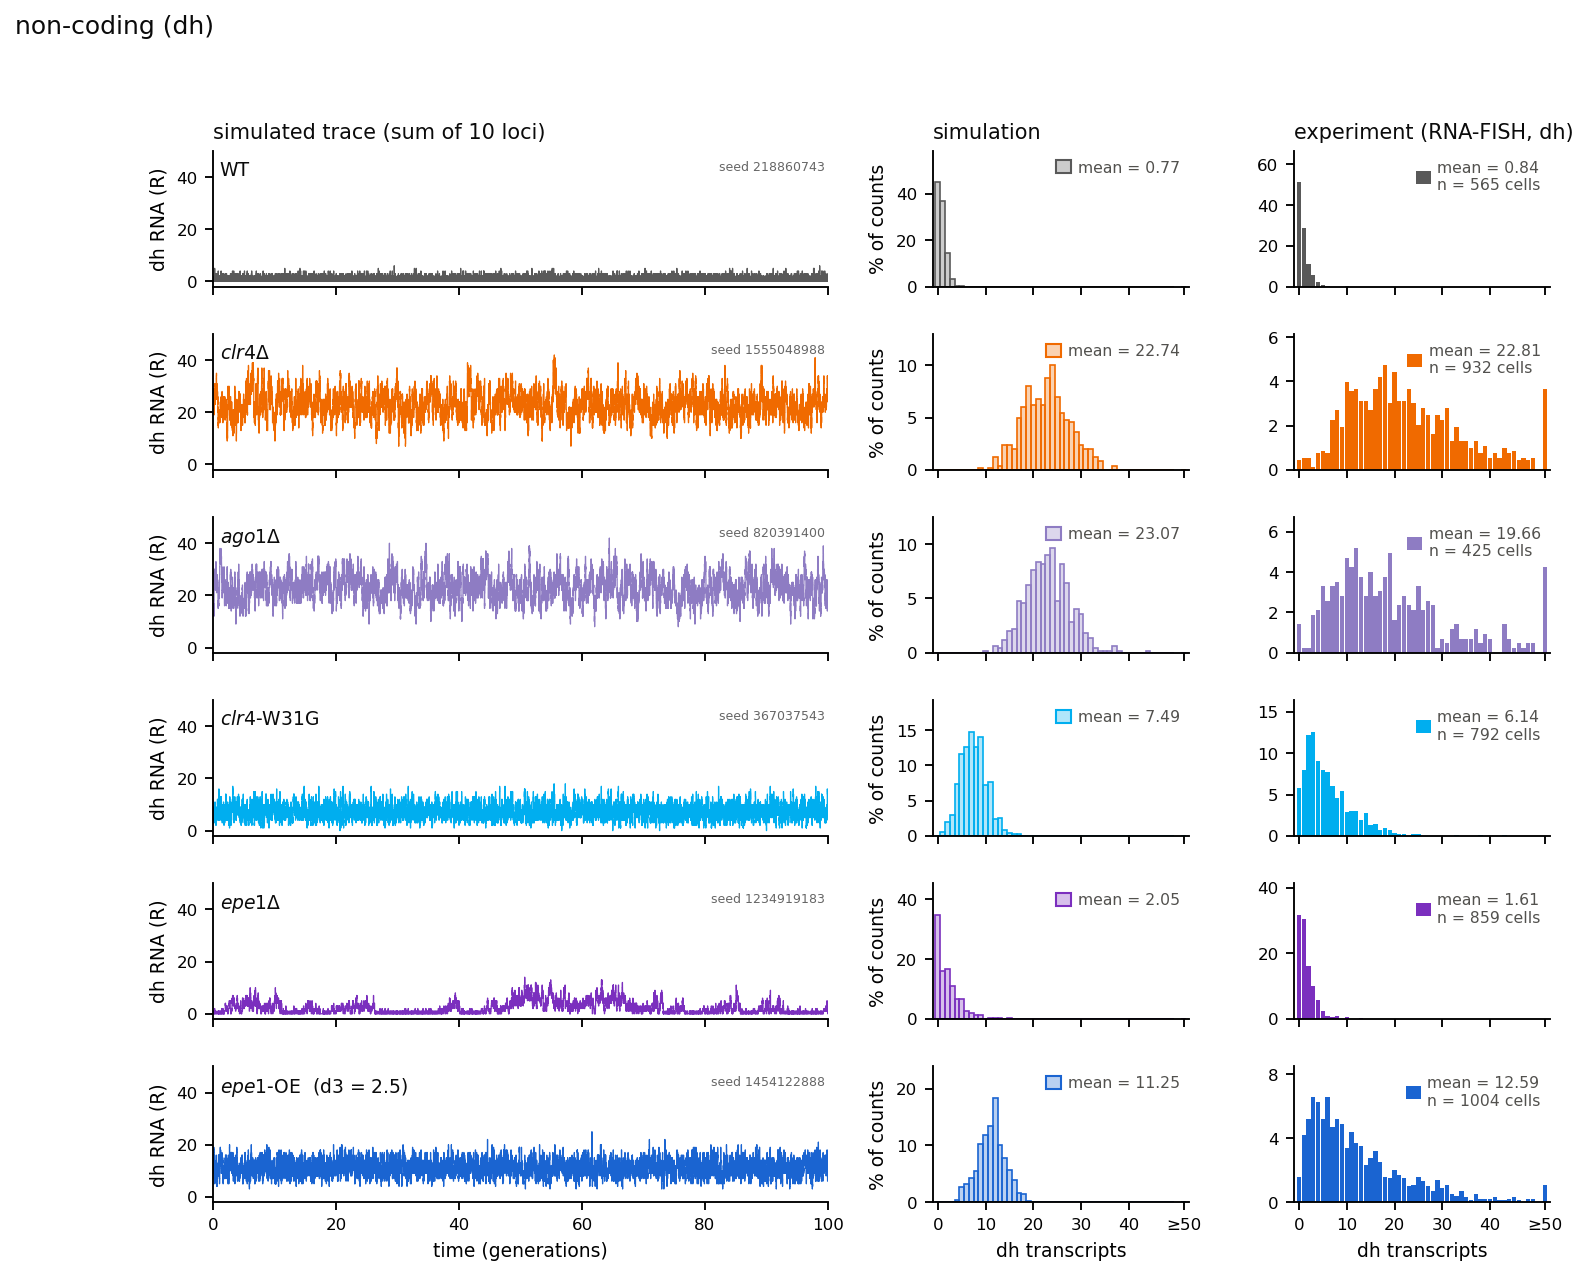

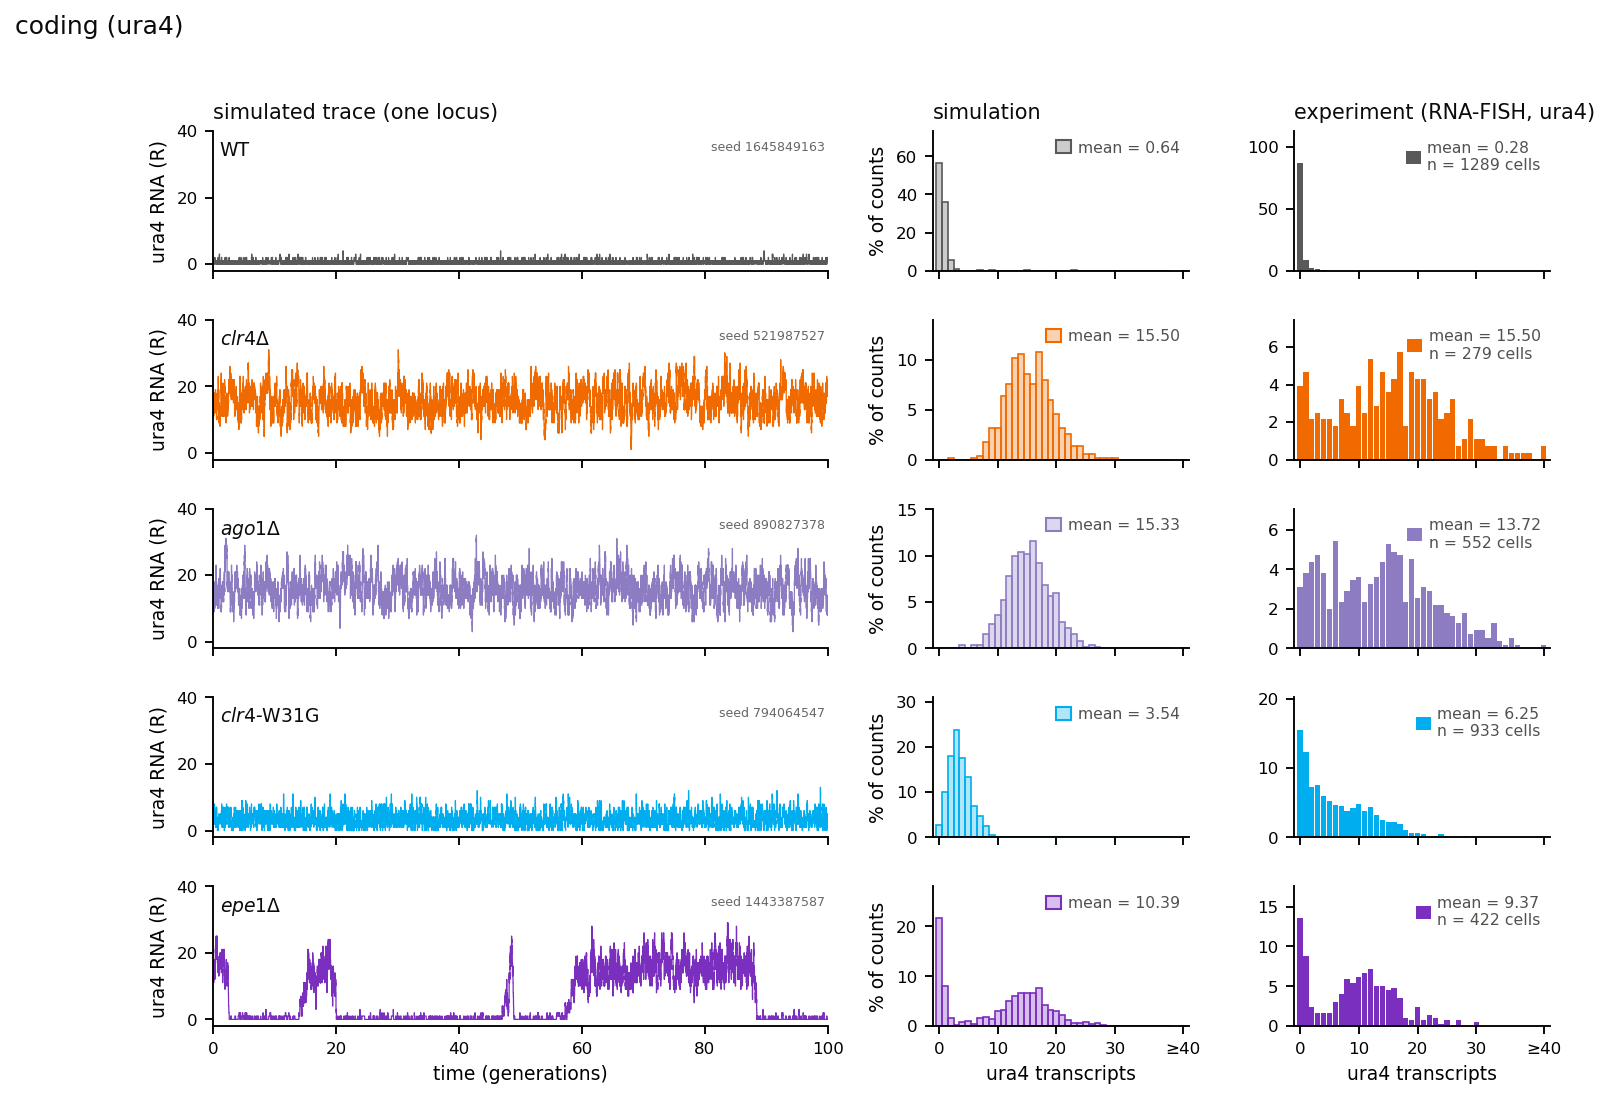

In [18]:
# ---- R: simulated trace | simulation histogram | experiment histogram, one figure per parameter set ----
# Histograms: res["R"] (section 1) and exp_data (section 1b).  Traces are simulated here (new seed on every run).
# data from sections 1 and 1b are computed here if they are not in memory yet
plt.rcParams["axes.grid"] = False

if "res" not in globals(): res = make_res()
if "exp_data" not in globals(): exp_data = load_exp_data()
trace_store = globals().get("trace_store", {})
REUSE_SECTION2_TRACES = False                   # True: use the traces of section 2 instead (run section 2 first)
TNREC = (TGENS + TRACE_BURNIN) * 160                 # records per simulated trace
tg = np.arange(TGENS * 160) / 160                    # time axis of the part shown
SET_ORDER = ("non-coding", "coding")
SET_TAG   = {"non-coding": "dh_noncoding", "coding": "ura4_coding"}
SET_NAME  = {"non-coding": "non-coding (dh)", "coding": "coding (ura4)"}
GENE      = {"non-coding": "dh", "coding": "ura4"}
SKIP      = {"coding": ("epe1_OE",)}          # no epe1-OE for the coding set

def pct_clip(v, xm):
    """% of counts per whole-number bin 0 ... xm-1, plus a last bin for everything >= xm."""
    edges = -0.5 + np.arange(xm + 2)
    return 100.0 * np.histogram(np.minimum(v, xm), bins=edges)[0] / len(v)

def mean_legend(ax, handle, text):
    ax.legend([handle], [text], loc="upper right", frameon=False, fontsize=7.5, labelcolor=INK2,
              handlelength=1.0, handleheight=0.9, handletextpad=0.4, borderaxespad=0.2)

for sname in SET_ORDER:
    geno = [g for g in GENOS if GENO_KEY[g[0]] not in SKIP.get(sname, ()) and (sname, g[0]) in res["R"]]
    xm, nl = XMAX_R[sname], NLOCI_SUM[sname]
    ctr = np.append(np.arange(xm), xm + 1.5)           # the ">= xm" bar sits apart
    ticks = list(range(0, xm, 10)) + [xm + 1.5]
    tlabs = [str(t) for t in range(0, xm, 10)] + ["\u2265%d" % xm]
    with plt.rc_context(RC):
        fig, axes = plt.subplots(len(geno), 3, figsize=(11.5, 1.35 * len(geno) + 1.0),
                                 gridspec_kw={"width_ratios": [2.4, 1, 1], "wspace": 0.28, "hspace": 0.35})
        for r, geno_r in enumerate(geno):
            lab, *_, col = geno_r
            if REUSE_SECTION2_TRACES and (sname, lab) in trace_store:
                R, seed = trace_store[(sname, lab)]["R"], trace_store[(sname, lab)]["seed"]
            else:
                R, M, S, seed = run_locus(sname, geno_r, TGENS + TRACE_BURNIN, TNREC) if nl == 1 else run_loci(sname, geno_r, TGENS + TRACE_BURNIN, TNREC, nl)
                R = cut_burnin(R, TGENS + TRACE_BURNIN)
            T = res["R"][(sname, lab)]; E = exp_data.get((sname, lab))
            fs = pct_clip(T, xm); fe = pct_clip(E, xm) if E is not None else np.zeros_like(fs)
            ymax_s = ymax_e = max(fs.max(), fe.max()) * 1.3          # shared y scale
            if EXP_OWN_YSCALE: ymax_s, ymax_e = fs.max() * 1.3, (fe.max() if E is not None else fs.max()) * 1.3
            ax = axes[r, 0]
            draw_trace(ax, tg[:len(R)], R, col)
            style_trace_axes(ax, xlim=(0, TGENS), ylim=(-2, xm), ylabel="%s RNA (R)" % GENE[sname])
            ax.text(0.01, 0.93, lab + ("  (d3 = %.1f)" % geno_r[4] if "OE" in lab else ""), transform=ax.transAxes,
                    va="top", fontsize=9, color=INK)
            ax.text(0.995, 0.93, "seed %d" % seed, transform=ax.transAxes, va="top", ha="right", fontsize=6, color="#666666")
            if r == 0: ax.set_title("simulated trace (" + ("sum of %d loci)" % nl if nl > 1 else "one locus)"),
                                    loc="left", fontsize=10, color=INK)
            # simulation histogram
            ax = axes[r, 1]
            ax.bar(ctr, fs, width=1, facecolor=mcolors.to_rgba(col, 0.30), edgecolor=col, linewidth=HIST_LW)
            mean_legend(ax, Patch(facecolor=mcolors.to_rgba(col, 0.30), edgecolor=col), "mean = %.2f" % T.mean())
            if r == 0: ax.set_title("simulation", loc="left", fontsize=10, color=INK)
            axes[r, 1].set_ylabel("% of counts")
            # experiment histogram
            ax = axes[r, 2]
            if E is not None:
                ax.bar(ctr, fe, width=0.9, facecolor=col, edgecolor="none")
                mean_legend(ax, Patch(facecolor=col), "mean = %.2f\nn = %d cells" % (E.mean(), len(E)))
            if r == 0: ax.set_title("experiment (RNA-FISH, %s)" % GENE[sname], loc="left", fontsize=10, color=INK)
            for ax, ym in zip(axes[r, 1:], (ymax_s, ymax_e)):
                ax.set_xlim(-1, xm + 2.6); ax.set_ylim(0, ym); ax.set_xticks(ticks); ax.set_xticklabels(tlabs)
                for ax, ym in zip(axes[r, 1:], (ymax_s, ymax_e)):
                    ax.set_xlim(-1, xm + 2.6); ax.set_ylim(0, ym); ax.set_xticks(ticks); ax.set_xticklabels(tlabs)
            # epe1-OE, non-coding (dh): experiment histogram y ticks 0, 4, 8
            if sname == "non-coding" and GENO_KEY[lab] == "epe1_OE":
                ax_e = axes[r, 2]
                ax_e.set_ylim(0, 8.5)
                ax_e.set_yticks([0, 4, 8])
        for c in range(3):
            axes[-1, c].set_xlabel("time (generations)" if c == 0 else "%s transcripts" % GENE[sname])
            for r in range(len(geno) - 1):
                if c == 0: axes[r, c].set_xticklabels([])
                else: axes[r, c].tick_params(labelbottom=False)
        fig.suptitle(SET_NAME[sname], x=0.01, ha="left", fontsize=12, color=INK)
        save_fig(fig, SET_TAG[sname] + "_trace_sim_exp")
        plt.show()

## 5. Panels: R, S, M traces
Run the "Panel settings" cell once. New traces are simulated in the next cell (`PANEL_FRESH = True`, new seeds on every run; burn-in removed), or the traces of section 2 are used (`PANEL_FRESH = False`). One figure per panel, R, S and M stacked, identical axes. 1: WT; 2: clr4Δ + ago1Δ; 3: WT + clr4-W31G + clr4Δ. The last cell adds panel 4 (epe1-OE) and panel 5 (epe1Δ, non-coding vs coding) from the same traces.

In [19]:
# ---- panel settings (axis limits, ticks, labels, colours; run once, then any panel cell) ----
# ---- panels 1-3 from trace_store (section 2): R, S, M stacked, same axes in all three ----
PANEL_SET   = "non-coding"
PANELS = {                                   # panel -> genotypes, drawn in this order (later ones on top)
    "1": ["WT"],
    "2": ["clr4_del", "ago1_del"],
    "3": ["WT", "clr4_W31G", "clr4_del"],
}
PANEL_COLORS = {"WT": "#595959", "clr4_del": "#f06a00", "ago1_del": "#8e7cc3", "clr4_W31G": "#00aeef"}

# axis limits and ticks (identical for all panels)
PANEL_YLIM  = {"R": (-2, XMAX_R[PANEL_SET]), "S": (-50, 1100), "M": (-0.05, 1)}
PANEL_YTICK = {"R": [0, 25, 50], "S": [0, 500, 1000], "M": [0, 0.5, 1]}              # None = automatic ticks
PANEL_YLAB  = {"R": "dh RNA (R)", "S": "siRNA (S)", "M": "methylation fraction"}
PANEL_XLIM  = (0, TGENS)

PANEL_LABEL = {GENO_KEY[g[0]]: g[0] for g in GENOS}                # key -> label
# fixed canvas: three axes of the same size
PANEL_FIGSIZE = (6, 5.9)
_ax_h, _gap, _top, _left, _w = 1.45, 0.35, 0.15, 0.13, 0.85            # inches (h, gap, top margin) and fractions (left, width)
PANEL_RECTS = [[_left, 1 - (_top + (i + 1) * _ax_h + i * _gap) / PANEL_FIGSIZE[1], _w, _ax_h / PANEL_FIGSIZE[1]] for i in range(3)]

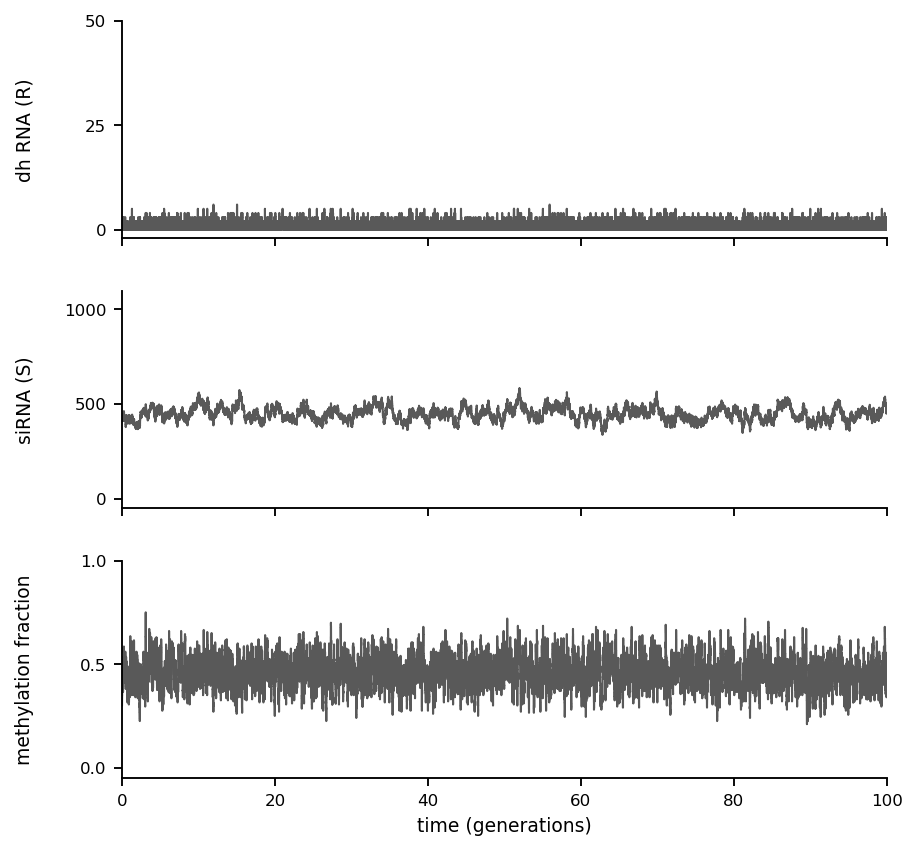

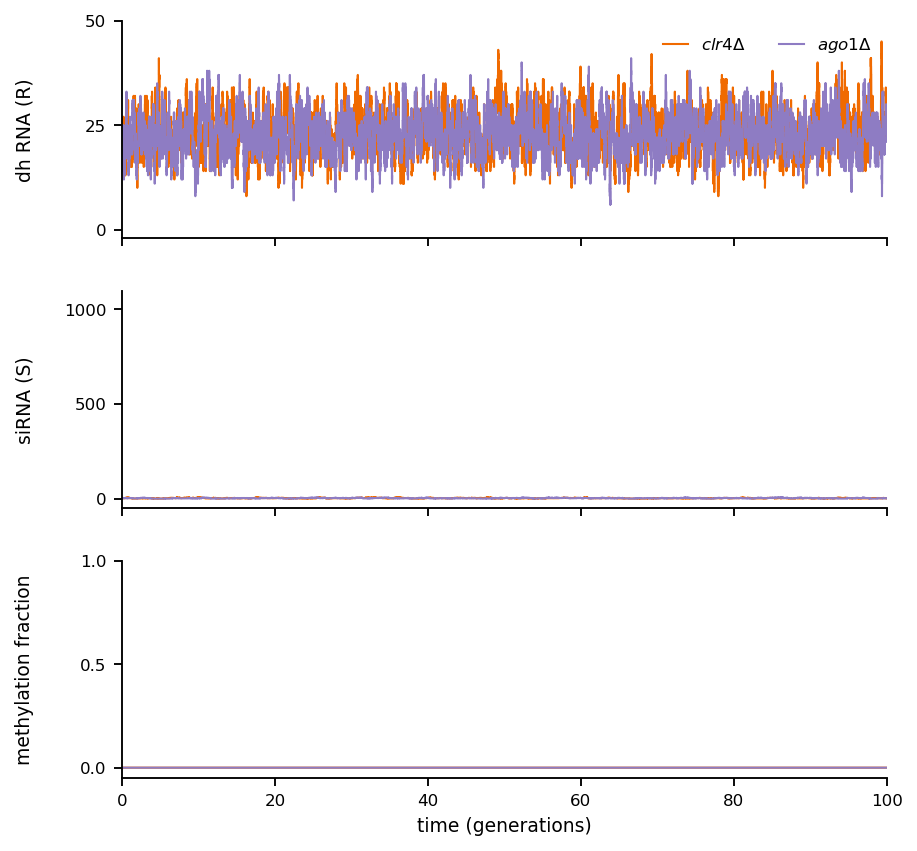

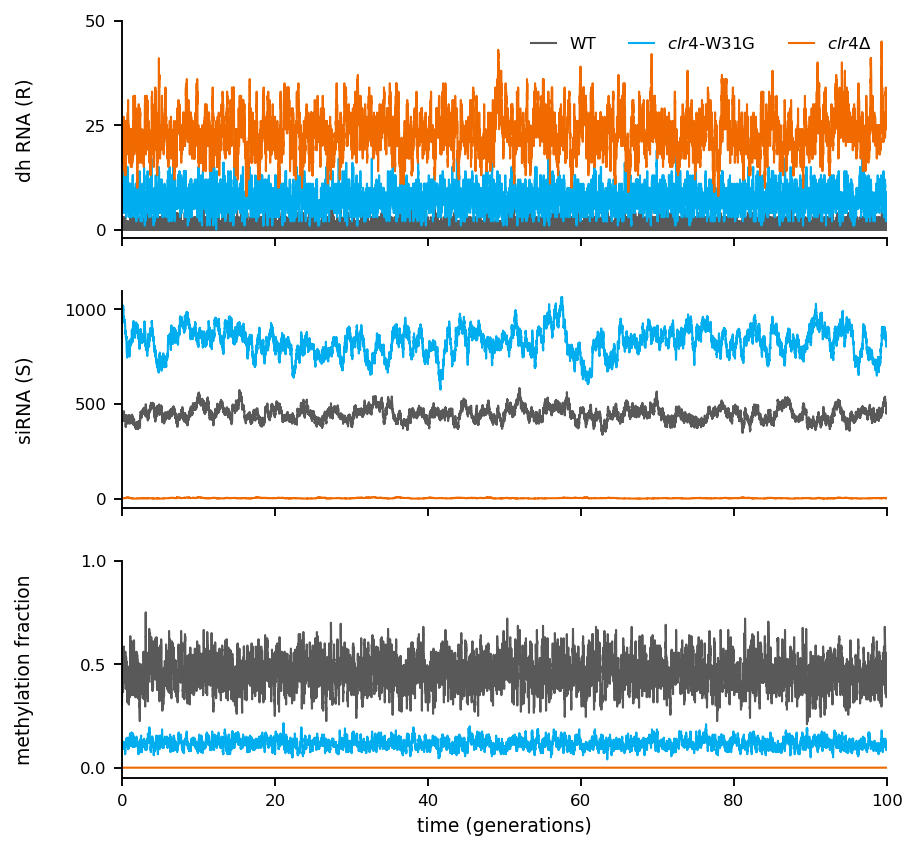

In [20]:
# ---- panels 1-3: simulate (or reuse) the traces and plot ----
# Needs the setup cells and the "Panel settings" cell above.
need("PANEL_RECTS", "run the Panel settings cell first")
needed = {k for ks in PANELS.values() for k in ks}
PANEL_FRESH = True                           # True: simulate new traces here (new seeds on every run); False: use the traces of section 2
if PANEL_FRESH:                                # also simulates what panels 4 and 5 need (epe1-OE, epe1D non-coding and coding)
    trace_store = globals().get("trace_store", {})
    _by_key = {GENO_KEY[g[0]]: g for g in GENOS}
    for _s, _k in sorted({(PANEL_SET, k) for k in needed | {"epe1_del", "epe1_OE"}} | {("coding", "epe1_del")}):
        trace_store[(_s, _by_key[_k][0])] = sim_panel_trace(_s, _by_key[_k])
missing = [PANEL_LABEL[k] for k in needed if (PANEL_SET, PANEL_LABEL[k]) not in trace_store]
assert not missing, "run section 2 first or set PANEL_FRESH = True (trace_store has no trace for %s)" % missing
for q in "RSM":                                                    # warn if a trace leaves the y-range
    top = max(trace_store[(PANEL_SET, PANEL_LABEL[k])][q].max() for k in needed)
    if top > PANEL_YLIM[q][1]: print("warning: %s reaches %.4g, above the y-limit %.4g" % (q, top, PANEL_YLIM[q][1]))

for tag, keys in PANELS.items():
    plot_trace_panel(keys, "dh_RSM_panel_%s_%s" % (tag, "_".join(keys)))
    plt.show()

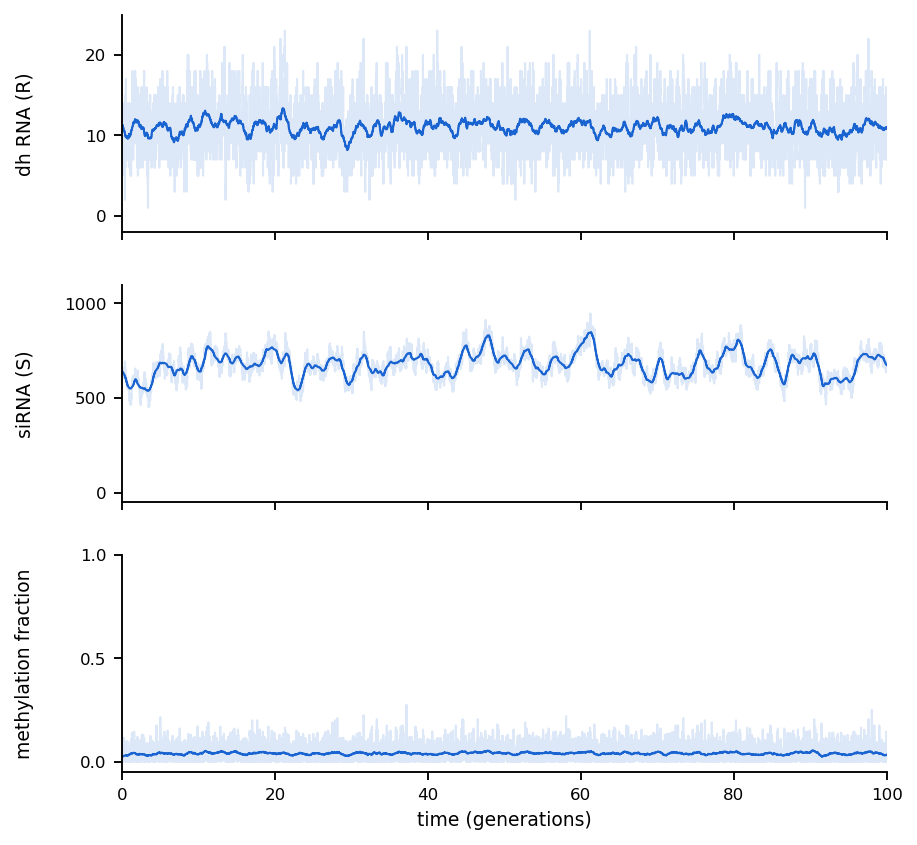

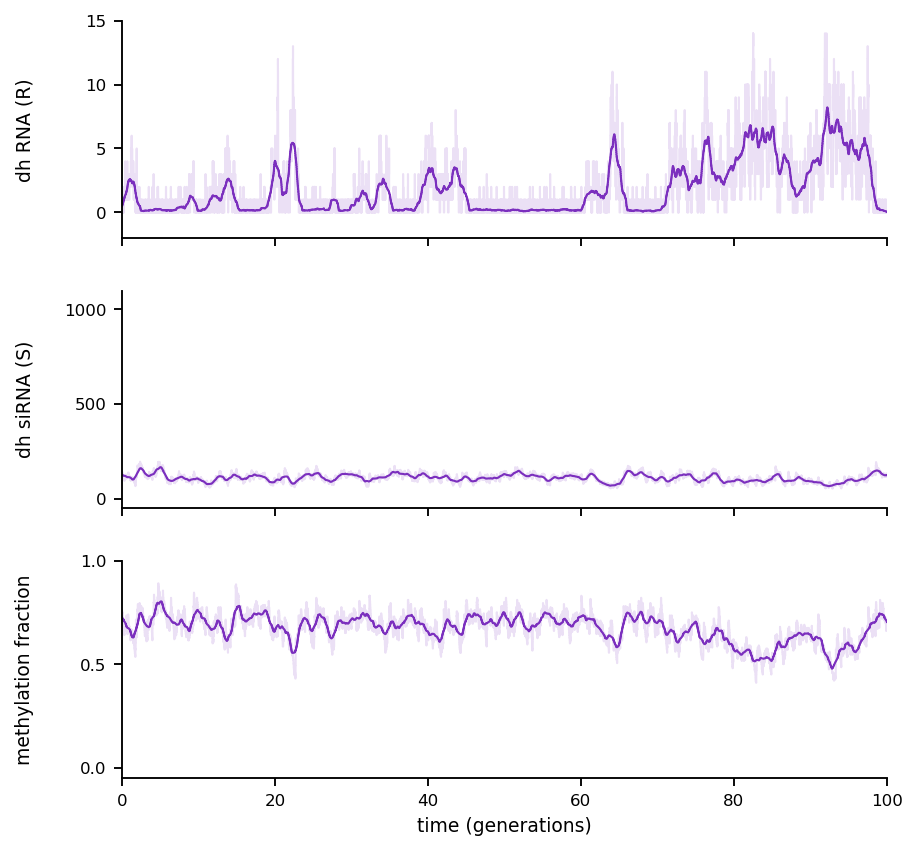

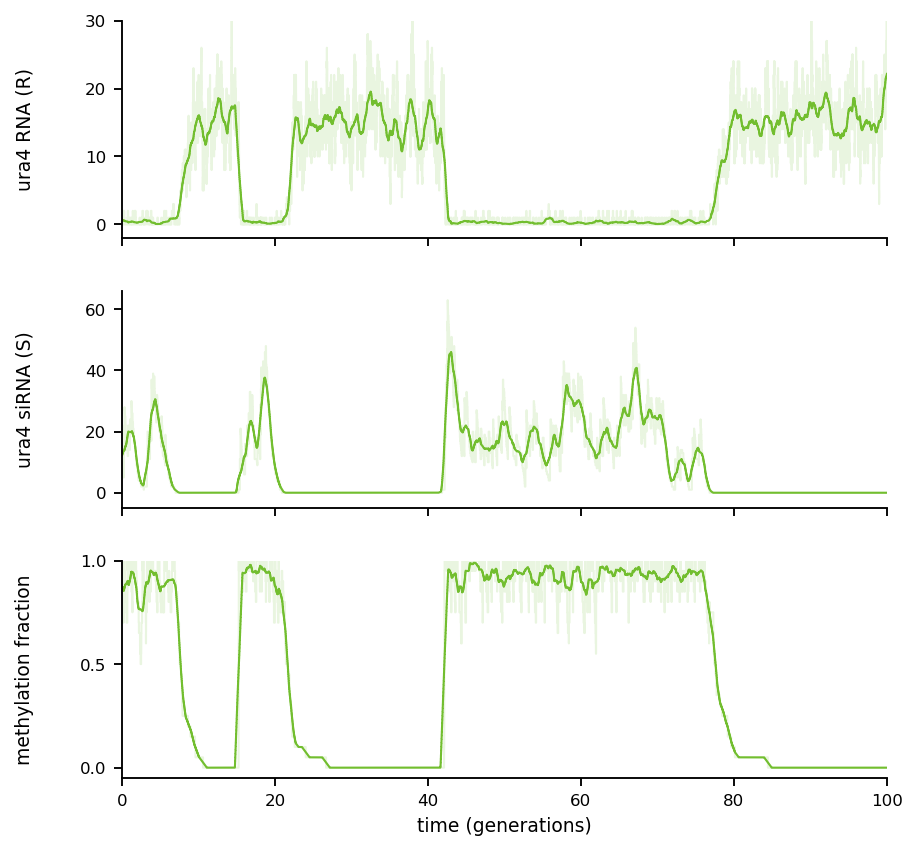

In [23]:
trace_store.clear()
# ---- panel 4 (epe1-OE) and panel 5 (epe1D, non-coding and coding as separate plots); all with raw trace + moving average ----
# Needs the setup cells and the "Panel settings" cell. Traces come from trace_store; any that are missing are simulated here.
import colorsys
from matplotlib.colors import to_rgb, to_hex
from scipy.ndimage import uniform_filter1d

need("PANEL_RECTS", "run the Panel settings cell first")
trace_store = globals().get("trace_store", {})
EPE1D_KEY = "epe1_del"
COL_NC = [g[5] for g in GENOS if GENO_KEY[g[0]] == EPE1D_KEY][0]           # non-coding
_h, _s, _v = colorsys.rgb_to_hsv(*to_rgb(COL_NC))
COL_CD = to_hex(colorsys.hsv_to_rgb((_h + 0.5) % 1.0, _s, _v))              # complementary hue: coding
PANEL_COLORS[EPE1D_KEY] = COL_NC
EPE1OE_KEY = "epe1_OE"
PANEL_COLORS[EPE1OE_KEY] = [g[5] for g in GENOS if GENO_KEY[g[0]] == EPE1OE_KEY][0]

# panel 4 axes (epe1-OE, non-coding): R to 25
P4_R, P4_R_TICKS = (-2, 25), [0, 10, 20]
# panel 5 axes: non-coding and coding (coding S and both M axes: automatic / 0-1)
P5_R_LEFT,  P5_R_RIGHT  = (-2, 15), (-2, 30)
P5_R_LEFT_TICKS, P5_R_RIGHT_TICKS = [0, 5, 10, 15], [0, 10, 20, 30]
P5_S_LEFT,  P5_S_LEFT_TICKS = PANEL_YLIM["S"], PANEL_YTICK["S"]
# raw trace (transparent) with its moving average on top (panels 4 and 5)
P5_RAW_ALPHA = 0.15                                                        # opacity of the raw trace
P5_MA_WINDOW_MIN = 150                                                     # moving-average window in minutes (0 = none); 1 generation = 150 min
P5_MA_LW     = 1                                                           # moving-average line width
# simulate whatever traces are not in trace_store yet (nothing happens if panels 1-3 or section 2 ran before)
_by_key = {GENO_KEY[g[0]]: g for g in GENOS}
for _s, _k in (("non-coding", EPE1OE_KEY), ("non-coding", EPE1D_KEY), ("coding", EPE1D_KEY)):
    if (_s, PANEL_LABEL[_k]) not in trace_store: trace_store[(_s, PANEL_LABEL[_k])] = sim_panel_trace(_s, _by_key[_k])

def _xy(sname, q, key, ma=False):
    y = trace_store[(sname, PANEL_LABEL[key])][q]
    t = np.arange(len(y)) * TGENS / len(y)
    if ma and P5_MA_WINDOW_MIN > 0:                                         # centred moving average
        pts_per_min = len(y) / (TGENS * DIV)
        y = uniform_filter1d(np.asarray(y, float), size=max(1, int(round(P5_MA_WINDOW_MIN * pts_per_min))), mode="nearest")
    return t, y

def draw_raw_ma(ax, sname, q, color, key):
    """Raw trace (transparent) with its moving average on top."""
    t, y = _xy(sname, q, key); draw_trace(ax, t, y, color, lw=TRACE_LW_PUB, alpha=P5_RAW_ALPHA if P5_MA_WINDOW_MIN > 0 else 1.0)
    if P5_MA_WINDOW_MIN > 0:
        t, y = _xy(sname, q, key, ma=True); draw_trace(ax, t, y, color, lw=P5_MA_LW)

def plot_trace_panel_single(sname, key, color, basename, lab_r, lab_s, r_lim, r_ticks, s_lim, s_ticks):
    """R, S, M traces (raw + moving average) of one genotype at one locus type, same canvas as panels 1-3."""
    lims = {"R": (r_lim, r_ticks), "S": (s_lim, s_ticks), "M": (PANEL_YLIM["M"], PANEL_YTICK["M"])}
    labs = {"R": lab_r, "S": lab_s, "M": PANEL_YLAB["M"]}
    with plt.rc_context(RC):
        fig = plt.figure(figsize=PANEL_FIGSIZE); fig.set_layout_engine(None)
        for i, q in enumerate("RSM"):
            ax = fig.add_axes(PANEL_RECTS[i])
            draw_raw_ma(ax, sname, q, color, key)
            style_trace_axes(ax, xlim=PANEL_XLIM, ylim=lims[q][0], ylabel=labs[q],
                             xlabel="time (generations)" if i == 2 else None, yticks=lims[q][1])
            if i < 2: ax.tick_params(labelbottom=False)
            ax.yaxis.set_label_coords(-0.115, 0.5)
    save_fig(fig, basename, tight=False)
    return fig

# ---- panel 4: epe1-OE (non-coding) ----
plot_trace_panel_single("non-coding", EPE1OE_KEY, PANEL_COLORS[EPE1OE_KEY], "dh_RSM_panel_4_%s" % EPE1OE_KEY,
                        PANEL_YLAB["R"], PANEL_YLAB["S"], P4_R, P4_R_TICKS, PANEL_YLIM["S"], PANEL_YTICK["S"])
plt.show()

# ---- panel 5: epe1D ----
# non-coding (dh)
plot_trace_panel_single("non-coding", EPE1D_KEY, COL_NC, "dh_RSM_panel_5_%s_noncoding" % EPE1D_KEY,
                        PANEL_YLAB["R"], "dh " + PANEL_YLAB["S"], P5_R_LEFT, P5_R_LEFT_TICKS, P5_S_LEFT, P5_S_LEFT_TICKS)
plt.show()
# coding (ura4); S: automatic upper limit
plot_trace_panel_single("coding", EPE1D_KEY, COL_CD, "dh_RSM_panel_5_%s_coding" % EPE1D_KEY,
                        "ura4 RNA (R)", "ura4 siRNA (S)", P5_R_RIGHT, P5_R_RIGHT_TICKS, (-5, None), None)
plt.show()

## 6. Phase plots and d3 scan
Each step 1 cell runs new simulations and stores the raw data; each step 2 cell plots the stored data without simulating.

In [21]:
# ---- helpers shared by the phase maps ----
from matplotlib.colors import LogNorm, Normalize, LinearSegmentedColormap
INKC = "black"                                   # marker, contour and label colour

def _edges(c):                                   # cell edges of a log-spaced grid
    if len(c) == 1: return np.array([c[0] / 2, c[0] * 2])
    lc = np.log10(c); d = lc[1] - lc[0]
    return 10 ** np.append(lc - d / 2, lc[-1] + d / 2)

def run_stat(runs, stat, below, nl):
    """Map values Z[i, j] and colour-bar label from runs[i, j, k] (last R of every run)."""
    if stat == "mean":   return runs.mean(axis=2), "mean R (sum of %d loci)" % nl
    if stat == "median": return np.median(runs, axis=2), "median R (sum of %d loci)" % nl
    if stat == "sem":    return runs.std(axis=2, ddof=1) / np.sqrt(runs.shape[2]), "s.e.m. of R"
    if stat == "fraction_silenced": return (runs < below).mean(axis=2), "fraction of runs with R < %g" % below
    raise ValueError("PLOT_STAT must be mean, median, sem or fraction_silenced")

def make_cmap_norm(cmap_color, cmap_name, log_color, vmin, vmax):
    cmap = LinearSegmentedColormap.from_list("white_to_colour", ["#ffffff", cmap_color]) if cmap_color else plt.get_cmap(cmap_name)
    return cmap, (LogNorm(vmin, vmax) if log_color else Normalize(vmin, vmax))

def draw_phase_map(ax, xv, yv, Zp, cmap, norm, shading, contours, annotate):
    """Heat map of Zp (rows = yv, columns = xv) on log-log axes. Returns the mesh for the colour bar."""
    if shading == "gouraud":
        pm = ax.pcolormesh(xv, yv, Zp, cmap=cmap, norm=norm, shading="gouraud", rasterized=True)
    else:
        pm = ax.pcolormesh(_edges(xv), _edges(yv), Zp, cmap=cmap, norm=norm, shading="flat", rasterized=True)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(_edges(xv)[0], _edges(xv)[-1]); ax.set_ylim(_edges(yv)[0], _edges(yv)[-1])
    if contours: ax.contour(xv, yv, Zp, levels=contours, colors=INKC, linewidths=1.0)
    if annotate:
        for i in range(len(yv)):
            for j in range(len(xv)):
                rgba = cmap(norm(Zp[i, j]))
                ax.text(xv[j], yv[i], "%.3g" % Zp[i, j], ha="center", va="center", fontsize=6,
                        color="white" if (0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]) < 0.5 else "black")
    return pm

In [22]:
# ---- phase map, step 1: simulate non-coding R on a (gamma, e_nuc) grid and store the data ----
# Every grid point: PHASE_RUNS runs of RUN_GENS generations (sum of NLOCI_SUM loci), last value kept.
# Raw values go to phase_data and PHASE_FILE.  Other parameters: WT non-coding.
import time

# ============================ SETTINGS ============================
PHASE_SET     = "non-coding"
PHASE_RUNS    = 40            # runs per grid point
PHASE_N_GAMMA = 21              # grid points for gamma
PHASE_N_ENUC  = 21              # grid points for e_nuc
PHASE_GAMMA   = (1e-3, 1e1)    # gamma range (log-spaced); WT = 1
PHASE_ENUC    = (1e-5, 1e-1)   # e_nuc range (log-spaced); WT = 0.01
PHASE_FILE    = OUTDIR / "phase_R_gamma_enuc.npz"
PHASE_LOAD_IF_EXISTS = False   # True: load PHASE_FILE instead of simulating
# ==================================================================

_PP = {**SHARED, **PARAM_SETS[PHASE_SET]}
_NL = NLOCI_SUM[PHASE_SET]

def sim_R_runs(gamma, e_nuc, nruns):
    """Last R (sum of _NL loci) of `nruns` runs at one (gamma, e_nuc)."""
    geno = ("pt", gamma / _PP["GAM"], 1, e_nuc / _PP["E_NUC"], _PP["D3"], "k")     # genotype tuple
    R = final_states(PHASE_SET, geno, RUN_GENS, nruns * _NL)[0]
    return R.reshape(nruns, _NL).sum(axis=1)

if PHASE_LOAD_IF_EXISTS and PHASE_FILE.exists():
    _f = np.load(PHASE_FILE)
    phase_data = {k: _f[k] for k in ("gamma", "enuc", "runs")}
    print("loaded", PHASE_FILE, "  grid %d x %d, %d runs per point" % (len(phase_data["gamma"]), len(phase_data["enuc"]), phase_data["runs"].shape[2]))
else:
    gam  = np.logspace(*np.log10(PHASE_GAMMA), PHASE_N_GAMMA)
    enuc = np.logspace(*np.log10(PHASE_ENUC),  PHASE_N_ENUC)
    runs = np.zeros((len(gam), len(enuc), PHASE_RUNS))                 # runs[i, j, k]: gamma[i], e_nuc[j], run k
    t0 = time.time()
    for i, g in enumerate(gam):
        for j, e in enumerate(enuc):
            runs[i, j] = sim_R_runs(g, e, PHASE_RUNS)
        print("gamma %9.3g  (%d/%d)   %.0f s" % (g, i + 1, len(gam), time.time() - t0))
    phase_data = {"gamma": gam, "enuc": enuc, "runs": runs}
    np.savez(PHASE_FILE, **phase_data)
    print("stored in memory (phase_data) and in", PHASE_FILE)

gamma     0.001  (1/21)   5 s
gamma   0.00158  (2/21)   10 s
gamma   0.00251  (3/21)   14 s
gamma   0.00398  (4/21)   19 s
gamma   0.00631  (5/21)   25 s
gamma      0.01  (6/21)   30 s
gamma    0.0158  (7/21)   36 s
gamma    0.0251  (8/21)   44 s
gamma    0.0398  (9/21)   53 s
gamma    0.0631  (10/21)   64 s
gamma       0.1  (11/21)   76 s
gamma     0.158  (12/21)   88 s
gamma     0.251  (13/21)   101 s
gamma     0.398  (14/21)   113 s
gamma     0.631  (15/21)   126 s
gamma         1  (16/21)   138 s
gamma      1.58  (17/21)   150 s
gamma      2.51  (18/21)   162 s
gamma      3.98  (19/21)   173 s
gamma      6.31  (20/21)   184 s
gamma        10  (21/21)   195 s
stored in memory (phase_data) and in /Users/sumanth/Library/CloudStorage/Box-Box/Manuscript_RNAi/Manuscript_10152026/simulations/phase_R_gamma_enuc.npz


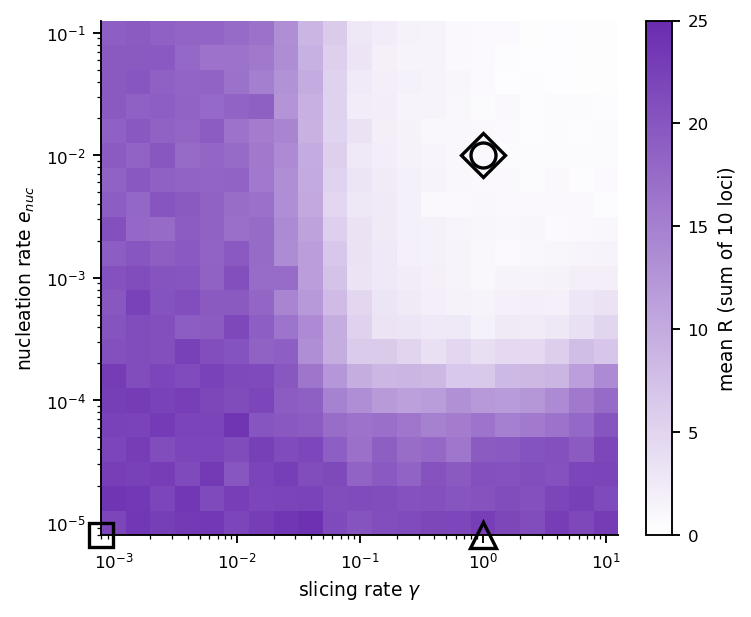

In [29]:
# ---- phase map, step 2: plot the stored data (no simulation) ----
# x = gamma, y = e_nuc.  Genotypes are marked at their own (gamma, e_nuc); * = e_RW = 0 (the map is at the WT e_RW).
# A value of 0 cannot be shown on a log axis, so it is drawn on the axis line.

plt.rcParams["svg.fonttype"] = "none"   # SVG: keep text as live text, not outlines
plt.rcParams["pdf.fonttype"] = 42       # PDF/EPS: embed TrueType so text stays editable
plt.rcParams["ps.fonttype"]  = 42

# ============================ PLOT FORMAT ============================
PLOT_STAT    = "mean"          # "mean", "median", "sem" or "fraction_silenced"
SILENCED_BELOW = 3             # fraction_silenced: fraction of runs with R below this
CMAP_COLOR   = "#6a2cb0"       # white (low) to this colour (high); None = use CMAP
CMAP         = "viridis"       # used only if CMAP_COLOR is None
VMIN, VMAX   = 0, 25           # colour limits (None = automatic)
LOG_COLOR    = False           # logarithmic colour scale
SHADING      = "flat"          # "flat" (one block per grid point) or "gouraud"
CONTOURS     = None            # e.g. [5, 10, 15]
ANNOTATE     = False           # value in every block
SHOW_GENOTYPES = ["WT", "ago1_del", "clr4_del", "clr4_W31G"]   # keys of GENO_KEY; [] = none
SHOW_LABELS  = False           # True: write the genotype name next to each marker
FIGSIZE      = (4.9, 4.0)
PLOT_NAME    = "dh_phase_R_gamma_enuc_plot"
MARKER_SCALE = 1.5             # multiplies all genotype marker sizes (1.0 = original); keep identical in the e_RW cell
# marker shape per genotype (keep identical in the e_RW cell)
GENO_MARKER  = {"WT": "o", "ago1_del": "s", "clr4_del": "^", "clr4_W31G": "D"}
MARKER_MS    = {"o": 8, "s": 7.5, "^": 8.5, "D": 6.5}                     # base size per shape
LABEL_DIRS   = [(8, 12, "left"), (-8, 12, "right"), (8, -14, "left"), (-8, -14, "right")]   # labels at a shared spot
# plain-text labels (one editable text object each in Illustrator); keep identical in the e_RW cell
LABEL_TXT    = {"WT": "WT", "ago1_del": "ago1Δ", "clr4_del": "clr4Δ", "clr4_W31G": "clr4-W31G"}
# =====================================================================

_g, _e, _r = phase_data["gamma"], phase_data["enuc"], phase_data["runs"]
Z, clab = run_stat(_r, PLOT_STAT, SILENCED_BELOW, NLOCI_SUM["non-coding"])
Zp = Z.T                                          # rows = e_nuc (y), columns = gamma (x)
cmap, norm = make_cmap_norm(CMAP_COLOR, CMAP, LOG_COLOR, VMIN, VMAX)
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=FIGSIZE, constrained_layout=True)
    pm = draw_phase_map(ax, _g, _e, Zp, cmap, norm, SHADING, CONTOURS, ANNOTATE)
    # ---- genotypes at their own (gamma, e_nuc); genotypes at the same position are nested ----
    _GAM0, _ENUC0 = PARAM_SETS["non-coding"]["GAM"], SHARED["E_NUC"]
    _by_key = {GENO_KEY[g[0]]: g for g in GENOS}
    _spots = {}                                                      # (gamma, e_nuc) -> [(label, key)]
    for k in SHOW_GENOTYPES:
        lab, gs, uw, un = _by_key[k][:4]
        txt = LABEL_TXT[k] + ("*" if uw != 1 else "")
        _spots.setdefault((_GAM0 * gs, _ENUC0 * un), []).append((txt, k))
    _xlo, _ylo = _edges(_g)[0], _edges(_e)[0]
    for n, ((gx, ey), items) in enumerate(_spots.items()):
        px, py = (gx if gx > 0 else _xlo), (ey if ey > 0 else _ylo)
        extra = ", ".join(s for s, v in (("γ = 0", gx == 0), ("e_nuc = 0", ey == 0)) if v)
        for j, (txt, k) in enumerate(items):
            m = GENO_MARKER.get(k, "o")
            ax.plot(px, py, m, ms=(MARKER_MS[m] + 3.5 * j) * MARKER_SCALE, mfc="none", mec=INKC,
                    mew=1.6, clip_on=False, zorder=5 + j)
            if not SHOW_LABELS: continue
            dx, dy, ha = LABEL_DIRS[j % len(LABEL_DIRS)]
            if len(items) == 1:                                      # single genotype: stagger as before
                dx, dy, ha = 7, 9 + 11 * (n % 2), "left"
            ax.annotate(txt + ("  (%s)" % extra if extra else ""),
                        (px, py), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=7,
                        fontstyle=("normal" if k == "WT" else "italic"), color=INKC, zorder=8,
                        arrowprops=dict(arrowstyle="-", color=INKC, lw=0.6, shrinkA=0,
                                        shrinkB=(4 + 1.75 * j) * MARKER_SCALE))
    ax.set_xlabel(r"slicing rate $\gamma$"); ax.set_ylabel(r"nucleation rate $e_{nuc}$")
    cb = fig.colorbar(pm, ax=ax, label=clab); cb.outline.set_linewidth(0.9)
    save_fig(fig, PLOT_NAME)
    plt.show()

In [24]:
# ---- phase map e_RW vs gamma, step 1: simulate non-coding R on an (e_RW, gamma) grid and store the data ----
# Every grid point: ERW_RUNS runs of ERW_GENS generations (sum of NLOCI_SUM loci), last value kept.
# Raw values go to erw_data and ERW_FILE.  Other parameters: WT non-coding.
import time

# ============================ SETTINGS ============================
ERW_SET      = "non-coding"
ERW_RUNS     = 40             # runs per grid point
ERW_N_GAMMA  = 21               # grid points for gamma
ERW_N_ERW    = 21               # grid points for e_RW
ERW_GAMMA    = (1e-3, 1e1)     # gamma range (log-spaced); WT = 1
ERW_ERW      = (1e-2, 1e2)     # e_RW range (log-spaced); WT = 2
ERW_GENS     = RUN_GENS        # generations per run (last value kept)
ERW_START    = "silenced"      # "silenced" (R = 0, S = 20, M = 0.9) or "desilenced" (R = 5, S = 0, M = 0)
ERW_FILE     = OUTDIR / "phase_R_gamma_erw.npz"
ERW_LOAD_IF_EXISTS = False     # True: load ERW_FILE instead of simulating
# ==================================================================

_PE = {**SHARED, **PARAM_SETS[ERW_SET]}
_NLE = NLOCI_SUM[ERW_SET]
_IC = {"silenced": (0, 20, int(0.9 * N)), "desilenced": (5, 0, 0)}[ERW_START]     # (R, S, methylated nucleosomes)

def sim_R_runs_erw(gamma, e_rw, nruns):
    """Last R (sum of _NLE loci) of `nruns` runs at one (gamma, e_RW)."""
    geno = ("pt", gamma / _PE["GAM"], e_rw / _PE["E_RW"], 1, _PE["D3"], "k")        # genotype tuple
    R = final_states(ERW_SET, geno, ERW_GENS, nruns * _NLE, ic=_IC)[0]
    return R.reshape(nruns, _NLE).sum(axis=1)

if ERW_LOAD_IF_EXISTS and ERW_FILE.exists():
    _f = np.load(ERW_FILE)
    erw_data = {k: _f[k] for k in ("gamma", "erw", "runs")}
    print("loaded", ERW_FILE, "  grid %d x %d, %d runs per point" % (len(erw_data["gamma"]), len(erw_data["erw"]), erw_data["runs"].shape[2]))
else:
    gam = np.logspace(*np.log10(ERW_GAMMA), ERW_N_GAMMA)
    erw = np.logspace(*np.log10(ERW_ERW),   ERW_N_ERW)
    runs = np.zeros((len(gam), len(erw), ERW_RUNS))                    # runs[i, j, k]: gamma[i], e_RW[j], run k
    t0 = time.time()
    for i, g in enumerate(gam):
        for j, e in enumerate(erw):
            runs[i, j] = sim_R_runs_erw(g, e, ERW_RUNS)
        print("gamma %9.3g  (%d/%d)   %.0f s" % (g, i + 1, len(gam), time.time() - t0))
    erw_data = {"gamma": gam, "erw": erw, "runs": runs}
    np.savez(ERW_FILE, **erw_data)
    print("stored in memory (erw_data) and in", ERW_FILE)

gamma     0.001  (1/21)   5 s
gamma   0.00158  (2/21)   10 s
gamma   0.00251  (3/21)   15 s
gamma   0.00398  (4/21)   20 s
gamma   0.00631  (5/21)   26 s
gamma      0.01  (6/21)   32 s
gamma    0.0158  (7/21)   38 s
gamma    0.0251  (8/21)   46 s
gamma    0.0398  (9/21)   56 s
gamma    0.0631  (10/21)   68 s
gamma       0.1  (11/21)   81 s
gamma     0.158  (12/21)   94 s
gamma     0.251  (13/21)   108 s
gamma     0.398  (14/21)   122 s
gamma     0.631  (15/21)   136 s
gamma         1  (16/21)   150 s
gamma      1.58  (17/21)   164 s
gamma      2.51  (18/21)   178 s
gamma      3.98  (19/21)   193 s
gamma      6.31  (20/21)   207 s
gamma        10  (21/21)   222 s
stored in memory (erw_data) and in /Users/sumanth/Library/CloudStorage/Box-Box/Manuscript_RNAi/Manuscript_10152026/simulations/phase_R_gamma_erw.npz


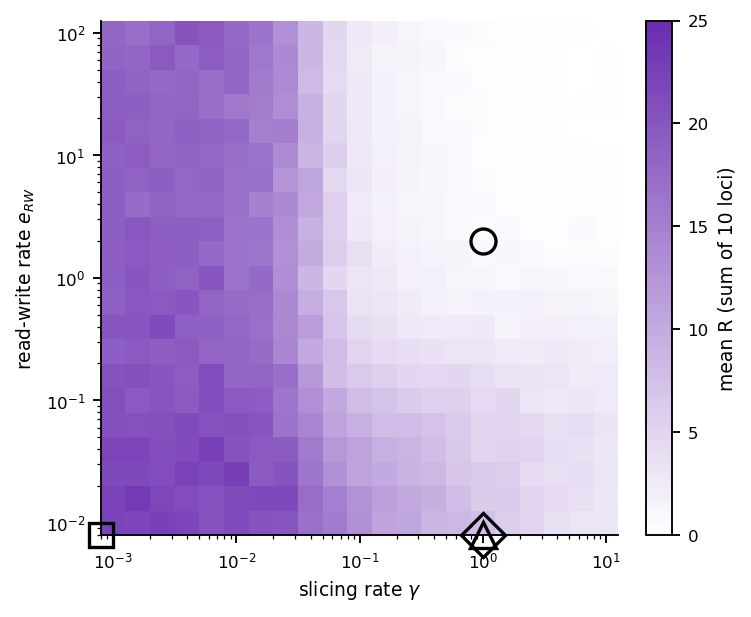

In [30]:
# ---- phase map e_RW vs gamma, step 2: plot the stored data (no simulation) ----
# Default x = gamma, y = e_RW (SWAP_AXES flips them).  Genotypes are marked at their own values; a value of 0 is drawn on the axis line.

plt.rcParams["svg.fonttype"] = "none"   # SVG: keep text as live text, not outlines
plt.rcParams["pdf.fonttype"] = 42       # PDF/EPS: embed TrueType so text stays editable
plt.rcParams["ps.fonttype"]  = 42

# ============================ PLOT FORMAT ============================
PLOT_STAT    = "mean"          # "mean", "median", "sem" or "fraction_silenced"
SILENCED_BELOW = 3             # fraction_silenced: fraction of runs with R below this
SWAP_AXES    = False           # False: x = gamma, y = e_RW;  True: x = e_RW, y = gamma
CMAP_COLOR   = "#6a2cb0"       # white (low) to this colour (high); None = use CMAP
CMAP         = "viridis"       # used only if CMAP_COLOR is None
VMIN, VMAX   = 0, 25           # colour limits (None = automatic)
LOG_COLOR    = False           # logarithmic colour scale
SHADING      = "flat"          # "flat" (one block per grid point) or "gouraud"
CONTOURS     = None            # e.g. [5, 10, 15]
ANNOTATE     = False           # value in every block
SHOW_GENOTYPES = ["WT", "ago1_del", "clr4_del", "clr4_W31G"]   # keys of GENO_KEY; [] = none
SHOW_LABELS  = False           # True: write the genotype name next to each marker
FIGSIZE      = (4.9, 4.0)
PLOT_NAME    = "dh_phase_R_erw_gamma_plot"
MARKER_SCALE = 1.5             # multiplies all genotype marker sizes (1.0 = original); keep identical in the e_nuc cell
# marker shape per genotype (keep identical in the e_nuc cell)
GENO_MARKER  = {"WT": "o", "ago1_del": "s", "clr4_del": "^", "clr4_W31G": "D"}
MARKER_MS    = {"o": 8, "s": 7.5, "^": 8.5, "D": 6.5}                     # base size per shape
LABEL_DIRS   = [(8, 12, "left"), (-8, 12, "right"), (8, -14, "left"), (-8, -14, "right")]   # labels at a shared spot
# plain-text labels (one editable text object each in Illustrator); keep identical in the e_nuc cell
LABEL_TXT    = {"WT": "WT", "ago1_del": "ago1Δ", "clr4_del": "clr4Δ", "clr4_W31G": "clr4-W31G"}
# =====================================================================

_g, _e, _r = erw_data["gamma"], erw_data["erw"], erw_data["runs"]
Z, clab = run_stat(_r, PLOT_STAT, SILENCED_BELOW, NLOCI_SUM["non-coding"])      # Z[i, j]: gamma[i], e_RW[j]
if SWAP_AXES: xv, yv, Zp, xl, yl = _e, _g, Z, r"read-write rate $e_{RW}$", r"slicing rate $\gamma$"
else:         xv, yv, Zp, xl, yl = _g, _e, Z.T, r"slicing rate $\gamma$", r"read-write rate $e_{RW}$"
cmap, norm = make_cmap_norm(CMAP_COLOR, CMAP, LOG_COLOR, VMIN, VMAX)
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=FIGSIZE, constrained_layout=True)
    pm = draw_phase_map(ax, xv, yv, Zp, cmap, norm, SHADING, CONTOURS, ANNOTATE)
    # ---- genotypes at their own (gamma, e_RW); genotypes at the same position are nested ----
    _GAM0, _ERW0 = PARAM_SETS["non-coding"]["GAM"], SHARED["E_RW"]
    _by_key = {GENO_KEY[g[0]]: g for g in GENOS}
    _spots = {}                                                      # (x value, y value) -> [(label, key)]
    for k in SHOW_GENOTYPES:
        lab, gs, uw, un = _by_key[k][:4]
        gam_v, erw_v = _GAM0 * gs, _ERW0 * uw
        _spots.setdefault((erw_v, gam_v) if SWAP_AXES else (gam_v, erw_v), []).append((LABEL_TXT[k], k))
    _xlo, _ylo = _edges(xv)[0], _edges(yv)[0]
    _xname, _yname = ("e_RW", "γ") if SWAP_AXES else ("γ", "e_RW")
    for n, ((px_v, py_v), items) in enumerate(_spots.items()):
        px, py = (px_v if px_v > 0 else _xlo), (py_v if py_v > 0 else _ylo)
        zeros = [s for s, v in ((_xname + " = 0", px_v == 0), (_yname + " = 0", py_v == 0)) if v]
        _right = (np.log10(px) - np.log10(_xlo)) / (np.log10(_edges(xv)[-1]) - np.log10(_xlo)) > 0.55      # right half: label points left
        for j, (txt, k) in enumerate(items):
            m = GENO_MARKER.get(k, "o")
            ax.plot(px, py, m, ms=(MARKER_MS[m] + 3.5 * j) * MARKER_SCALE, mfc="none", mec=INKC,
                    mew=1.6, clip_on=False, zorder=5 + j)
            if not SHOW_LABELS: continue
            if len(items) == 1:                                      # single genotype: stagger as before
                dx, dy, ha = (-7 if _right else 7), 9 + 11 * (n % 2), ("right" if _right else "left")
            else:                                                    # shared spot: fan the labels out
                dx, dy, ha = LABEL_DIRS[j % len(LABEL_DIRS)]
                if _right: dx, ha = -dx, ("left" if ha == "right" else "right")
            ax.annotate(txt + ("\n(%s)" % ", ".join(zeros) if zeros else ""),
                        (px, py), xytext=(dx, dy), textcoords="offset points", fontsize=7,
                        fontstyle=("normal" if k == "WT" else "italic"), color=INKC, zorder=8, ha=ha,
                        arrowprops=dict(arrowstyle="-", color=INKC, lw=0.6, shrinkA=0,
                                        shrinkB=(4 + 1.75 * j) * MARKER_SCALE))
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    cb = fig.colorbar(pm, ax=ax, label=clab); cb.outline.set_linewidth(0.9)
    save_fig(fig, PLOT_NAME)
    plt.show()

In [15]:
# ---- d3 scan, step 1: SIMULATE R, S and M while changing d3 (Epe1 demethylation rate) alone, and store the data ----
# Every d3 value: D3_RUNS independent runs of D3_GENS generations, each run = sum of NLOCI_SUM loci; the last value of each run is kept.
# R and S are summed over the loci, M is the methylation fraction (mean over the loci).  All raw values are stored (not only the mean),
# in memory (d3_data) and in OUTDIR/scan_d3.npz, so the next cell can re-plot any statistic without simulating again.
# All other parameters are those of the WT set.  Needs the settings, model and histogram sections (RUN_GENS, NLOCI_SUM) to have been run.
import time

# ============================ SETTINGS ============================
D3_SET     = "non-coding"
D3_RUNS    = 200               # independent runs averaged at every d3
D3_N       = 15               # number of d3 values (log-spaced)
D3_RANGE   = (1e-3, 1e1)       # d3 range; WT = 0.05, epe1-OE = 2.5
D3_ZERO    = True              # also simulate d3 = 0 (epe1D); it is drawn at the left edge of the log axis
D3_GENS    = RUN_GENS          # length of every run (generations); last value is kept
D3_START   = "silenced"        # "silenced" (R = 0, S = 20, M = 0.9, as in the histograms) or "desilenced" (R = 5, S = 0, M = 0)
D3_FILE    = OUTDIR / "scan_d3.npz"
D3_LOAD_IF_EXISTS = False      # True: if D3_FILE exists, load it instead of simulating
# ==================================================================

_P3 = {**SHARED, **PARAM_SETS[D3_SET]}
_NL3 = NLOCI_SUM[D3_SET]
_IC3 = {"silenced": (0, 20, int(0.9 * N)), "desilenced": (5, 0, 0)}[D3_START]          # (R, S, methylated nucleosomes)

def sim_d3_runs(d3, nruns):
    """R, S (sums over _NL3 loci) and M (mean methylation fraction) of the last value of `nruns` independent runs at one d3."""
    geno = ("pt", 1, 1, 1, d3, "k")                                                  # (label, GAM scale, E_RW scale, E_NUC scale, D3, colour)
    R, S, m, _ = final_states(D3_SET, geno, D3_GENS, nruns * _NL3, ic=_IC3)
    return (R.reshape(nruns, _NL3).sum(axis=1), S.reshape(nruns, _NL3).sum(axis=1), m.reshape(nruns, _NL3).mean(axis=1) / N)

if D3_LOAD_IF_EXISTS and D3_FILE.exists():
    _f = np.load(D3_FILE)
    d3_data = {k: _f[k] for k in ("d3", "R", "S", "M")}
    print("loaded", D3_FILE, "  %d d3 values, %d runs each" % (len(d3_data["d3"]), d3_data["R"].shape[1]))
else:
    d3v = np.logspace(*np.log10(D3_RANGE), D3_N)
    if D3_ZERO: d3v = np.insert(d3v, 0, 0.0)
    out = {q: np.zeros((len(d3v), D3_RUNS)) for q in "RSM"}
    t0 = time.time()
    for i, d in enumerate(d3v):
        out["R"][i], out["S"][i], out["M"][i] = sim_d3_runs(d, D3_RUNS)
        print("d3 %9.3g  (%d/%d)   %.0f s" % (d, i + 1, len(d3v), time.time() - t0))
    d3_data = {"d3": d3v, **out}
    np.savez(D3_FILE, **d3_data)
    print("stored in memory (d3_data) and in", D3_FILE)

d3         0  (1/16)   1 s
d3     0.001  (2/16)   1 s
d3   0.00193  (3/16)   2 s
d3   0.00373  (4/16)   3 s
d3    0.0072  (5/16)   4 s
d3    0.0139  (6/16)   6 s
d3    0.0268  (7/16)   8 s
d3    0.0518  (8/16)   12 s
d3       0.1  (9/16)   17 s
d3     0.193  (10/16)   24 s
d3     0.373  (11/16)   32 s
d3      0.72  (12/16)   42 s
d3      1.39  (13/16)   53 s
d3      2.68  (14/16)   64 s
d3      5.18  (15/16)   72 s
d3        10  (16/16)   74 s
stored in memory (d3_data) and in /Users/sumanth/Library/CloudStorage/Box-Box/Manuscript_RNAi/Manuscript_10152026/simulations2/scan_d3.npz


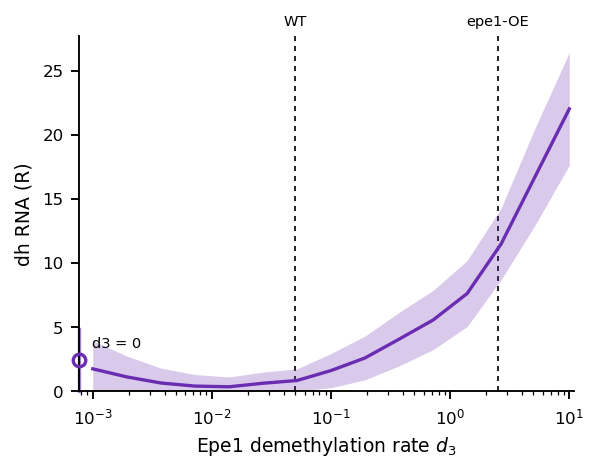

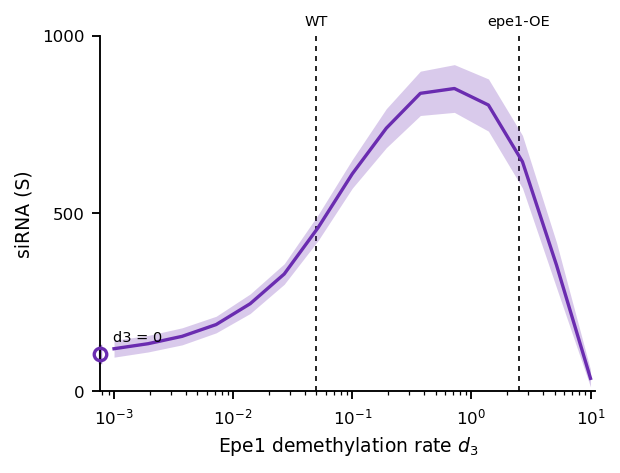

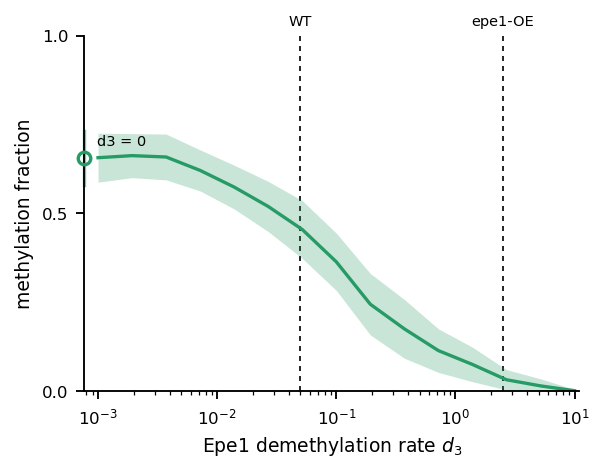

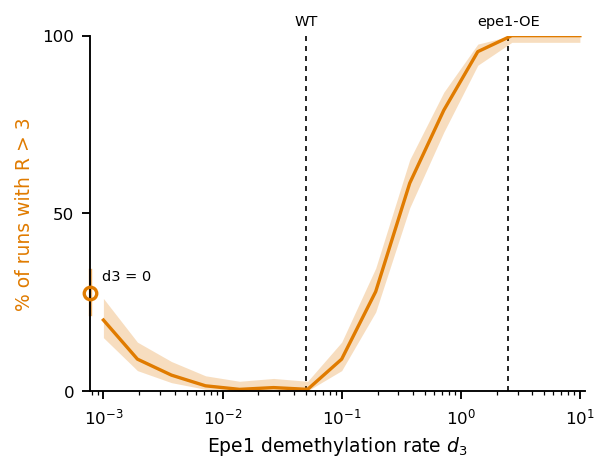

In [24]:
# ---- d3 scan, step 2: PLOT the stored data (no simulation): R, S, M and the percentage of high-R runs vs d3 (log axis) ----
# Uses d3_data from the previous cell (or after a restart: d3_data = dict(np.load(D3_FILE))).

# ============================ PLOT FORMAT ============================
D3_FIGURES   = ["R", "S", "M", "F"]   # "R", "S", "M" = value vs d3;  "F" = percentage of runs with R > D3_FRAC_THRESH
D3_CENTER    = "mean"          # line: "mean" or "median"
D3_BAND      = "sd"            # shaded band: "sd" (standard deviation), "sem" (standard error), "iqr" (25-75 %) or None
D3_COLOR     = "#6a2cb0"       # line and band colour (default for R and S)
D3_COLOR_BY_FIG = {"M": "#279b65"}   # per-figure override (M in emerald green); figures not listed use D3_COLOR
D3_BAND_ALPHA = 0.25
D3_LW        = 1.6             # line width
D3_MARKERS   = False            # a dot at every d3 value
D3_MARK_GENOTYPES = {"WT": 0.05, "epe1-OE": 2.5}   # dashed vertical lines with labels (d3 of each genotype); {} = none
D3_BODY      = (3.30, 2.37)    # size of the plotting area (inches, without labels) - the same in every figure
D3_MARGINS   = dict(left=0.72, bottom=0.58, top=0.28, right=0.14)   # space (inches) for tick labels / axis labels around the plotting area
D3_MARGIN_RIGHT_AXIS = 0.72    # right margin (inches) used instead of D3_MARGINS["right"] when the R figure has the right axis
D3_XLIM      = None            # x limits, e.g. (0.8, 30); None = from the smallest to the largest scanned d3, padded by D3_XPAD
D3_XPAD      = (1.3, 1.1)      # padding factors (left, right) around the scanned d3 values when D3_XLIM is None
D3_YLIM      = {"R": (0, None), "S": (0, 1000), "M": (0, 1)}   # None = automatic upper limit
D3_YTICK     = {"R": None, "S": [0, 500, 1000], "M": [0, 0.5, 1], "F": [0, 50, 100]}   # None = automatic ticks
D3_YLAB      = {"R": "dh RNA (R)", "S": "siRNA (S)", "M": "methylation fraction"}
# percentage of runs with R > threshold
D3_FRAC_THRESH = 3             # a run counts as high if its final R > this value
D3_FRAC_ABOVE = True           # True: R > threshold;  False: R <= threshold
D3_FRAC_ON_R = False           # True: also draw the percentage on a right y-axis of the R figure
D3_FRAC_COLOR = "#e07b00"      # percentage line, right axis and labels
D3_FRAC_BAND = "wilson"        # band around the percentage: "wilson" (95 % CI) or None
D3_FRAC_YLIM = (0, 100)        # percentage axis limits (right axis and the "F" figure)
D3_NAME      = "dh_d3_scan"    # files: dh_d3_scan_R, _S, _M, _F
# =====================================================================

_d3 = d3_data["d3"]
_pos = _d3 > 0
_xlo, _xhi = D3_XLIM if D3_XLIM else (_d3[_pos].min() / D3_XPAD[0], _d3.max() * D3_XPAD[1])      # left edge = where d3 = 0 (epe1D) is drawn
_FRAC_LAB = "%% of runs with R %s %g" % (">" if D3_FRAC_ABOVE else "≤", D3_FRAC_THRESH)
_TOP = {"M": 1, "F": 100}      # upper clip of the band per figure

def _stats(a):
    c = a.mean(axis=1) if D3_CENTER == "mean" else np.median(a, axis=1)
    if D3_BAND == "sd":    lo, hi = c - a.std(axis=1, ddof=1), c + a.std(axis=1, ddof=1)
    elif D3_BAND == "sem": lo, hi = c - a.std(axis=1, ddof=1) / np.sqrt(a.shape[1]), c + a.std(axis=1, ddof=1) / np.sqrt(a.shape[1])
    elif D3_BAND == "iqr": lo, hi = np.percentile(a, 25, axis=1), np.percentile(a, 75, axis=1)
    else:                  lo = hi = None
    return c, lo, hi

def _fraction(a):                                                  # percentage of runs above / below the threshold + Wilson 95 % CI
    n = a.shape[1]; k = (a > D3_FRAC_THRESH).sum(axis=1) if D3_FRAC_ABOVE else (a <= D3_FRAC_THRESH).sum(axis=1)
    p = k / n; z = 1.96; den = 1 + z**2 / n
    ctr = (p + z**2 / (2 * n)) / den; half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    p_lo, p_hi = (ctr - half, ctr + half) if D3_FRAC_BAND == "wilson" else (None, None)
    if p_lo is not None: p_lo, p_hi = 100 * p_lo, 100 * p_hi
    return 100 * p, p_lo, p_hi

def _draw(ax, c, lo, hi, color, top=None, label=True):
    """Line and band for d3 > 0; d3 = 0 (epe1D) is an open marker (+ its spread) on the left axis edge."""
    if lo is not None: ax.fill_between(_d3[_pos], np.maximum(lo[_pos], 0), hi[_pos] if top is None else np.minimum(hi[_pos], top), color=color, alpha=D3_BAND_ALPHA, lw=0)
    ax.plot(_d3[_pos], c[_pos], color=color, lw=D3_LW, marker="o" if D3_MARKERS else None, ms=3.5)
    if (~_pos).any():
        if lo is not None: ax.plot([_xlo, _xlo], [max(lo[~_pos][0], 0), hi[~_pos][0]], color=color, lw=D3_LW, alpha=0.6, clip_on=False)
        ax.plot(_xlo, c[~_pos][0], "o", ms=6, mfc="none", mec=color, mew=1.6, clip_on=False, zorder=5)
        if label: ax.annotate("d3 = 0", (_xlo, c[~_pos][0]), xytext=(6, 6), textcoords="offset points", fontsize=7)

_H = D3_MARGINS["bottom"] + D3_BODY[1] + D3_MARGINS["top"]
for q in D3_FIGURES:
    right_axis = D3_FRAC_ON_R and q == "R"
    c, lo, hi = _fraction(d3_data["R"]) if q == "F" else _stats(d3_data[q])
    _W = D3_MARGINS["left"] + D3_BODY[0] + (D3_MARGIN_RIGHT_AXIS if right_axis else D3_MARGINS["right"])
    with plt.rc_context(RC):
        fig = plt.figure(figsize=(_W, _H)); fig.set_layout_engine(None)
        ax = fig.add_axes([D3_MARGINS["left"] / _W, D3_MARGINS["bottom"] / _H, D3_BODY[0] / _W, D3_BODY[1] / _H])      # fixed plotting area
        _draw(ax, c, lo, hi, D3_FRAC_COLOR if q == "F" else D3_COLOR_BY_FIG.get(q, D3_COLOR), top=_TOP.get(q))
        for name, d in D3_MARK_GENOTYPES.items():
            if not (_xlo <= d <= _xhi): continue                         # genotype outside the scanned range: not drawn
            ax.axvline(d, color="black", lw=0.8, ls=(0, (3, 3)), zorder=0)
            ax.text(d, 1.02, name, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7)
        ax.set_xscale("log"); ax.set_xlim(_xlo, _xhi)
        ax.set_ylim(*(D3_FRAC_YLIM if q == "F" else D3_YLIM[q]))
        if D3_YTICK.get(q) is not None: ax.set_yticks(D3_YTICK[q])
        ax.set_xlabel(r"Epe1 demethylation rate $d_3$"); ax.set_ylabel(_FRAC_LAB if q == "F" else D3_YLAB[q])
        if q == "F": ax.yaxis.label.set_color(D3_FRAC_COLOR)
        if right_axis:                                                   # right axis: percentage of runs with R > threshold
            p, flo, fhi = _fraction(d3_data["R"])
            ax2 = ax.twinx()
            for sp in ("top", "left", "bottom"): ax2.spines[sp].set_visible(False)
            ax2.spines["right"].set_visible(True); ax2.spines["right"].set_linewidth(ax.spines["left"].get_linewidth()); ax2.spines["right"].set_color(D3_FRAC_COLOR)
            _draw(ax2, p, flo, fhi, D3_FRAC_COLOR, top=100, label=False)
            ax2.set_ylim(*D3_FRAC_YLIM)
            if D3_YTICK.get("F") is not None: ax2.set_yticks(D3_YTICK["F"])
            ax2.set_ylabel(_FRAC_LAB, color=D3_FRAC_COLOR); ax2.tick_params(axis="y", colors=D3_FRAC_COLOR)
    save_fig(fig, "%s_%s" % (D3_NAME, q), tight=False)
    plt.show()

In [17]:
import gillespy2; print(gillespy2.__version__)

1.8.3


In [18]:
# # ---- d3 scan, step 1: simulate R, S and M for different d3 (Epe1 demethylation rate) and store the data ----
# # Every d3 value: D3_RUNS runs of D3_GENS generations (sum of NLOCI_SUM loci), last value kept.
# # R, S are summed over the loci, M is the mean methylation fraction.  Raw values go to d3_data and D3_FILE.  Other parameters: WT.
# import time

# # ============================ SETTINGS ============================
# D3_SET     = "non-coding"
# D3_RUNS    = 200               # runs per d3
# D3_N       = 15               # number of d3 values
# D3_SPACE   = "linear"          # "linear" or "log" spacing of the d3 values
# D3_RANGE   = (0.0, 3)        # d3 range ("log" needs a lower value > 0); WT = 0.05, epe1-OE = 2.5
# D3_ZERO    = True              # also simulate d3 = 0 (epe1D)
# D3_GENS    = RUN_GENS          # generations per run (last value kept)
# D3_START   = "silenced"        # "silenced" (R = 0, S = 20, M = 0.9) or "desilenced" (R = 5, S = 0, M = 0)
# D3_FILE    = OUTDIR / "scan_d3.npz"
# D3_LOAD_IF_EXISTS = False      # True: load D3_FILE instead of simulating
# # ==================================================================

# _NL3 = NLOCI_SUM[D3_SET]
# _IC3 = {"silenced": (0, 20, int(0.9 * N)), "desilenced": (5, 0, 0)}[D3_START]          # (R, S, methylated nucleosomes)

# def sim_d3_runs(d3, nruns):
#     """R, S (sums over _NL3 loci) and M (mean methylation fraction) of `nruns` runs at one d3."""
#     geno = ("pt", 1, 1, 1, d3, "k")                                                  # genotype tuple
#     R, S, m, _ = final_states(D3_SET, geno, D3_GENS, nruns * _NL3, ic=_IC3)
#     return (R.reshape(nruns, _NL3).sum(axis=1), S.reshape(nruns, _NL3).sum(axis=1), m.reshape(nruns, _NL3).mean(axis=1) / N)

# if D3_LOAD_IF_EXISTS and D3_FILE.exists():
#     _f = np.load(D3_FILE)
#     d3_data = {k: _f[k] for k in ("d3", "R", "S", "M")}
#     print("loaded", D3_FILE, "  %d d3 values, %d runs each" % (len(d3_data["d3"]), d3_data["R"].shape[1]))
# else:
#     d3v = np.linspace(*D3_RANGE, D3_N) if D3_SPACE == "linear" else np.logspace(*np.log10(D3_RANGE), D3_N)
#     if D3_ZERO and 0.0 not in d3v: d3v = np.insert(d3v, 0, 0.0)
#     out = {q: np.zeros((len(d3v), D3_RUNS)) for q in "RSM"}
#     t0 = time.time()
#     for i, d in enumerate(d3v):
#         out["R"][i], out["S"][i], out["M"][i] = sim_d3_runs(d, D3_RUNS)
#         print("d3 %9.3g  (%d/%d)   %.0f s" % (d, i + 1, len(d3v), time.time() - t0))
#     d3_data = {"d3": d3v, **out}
#     np.savez(D3_FILE, **d3_data)
#     print("stored in memory (d3_data) and in", D3_FILE)

In [19]:
# # ---- d3 scan, step 2: plot the stored data (no simulation): R, S, M vs d3 and a low-d3 zoom ----
# # Uses d3_data from the previous cell (or d3_data = dict(np.load(D3_FILE))).

# # ============================ PLOT FORMAT ============================
# D3_FIGURES   = ["R", "S", "M"]  # any of "R", "S", "M" (full range) and "zoom" (see D3_ZOOM)
# D3_XSCALE    = "linear"        # full-range figures: "linear" or "log" (d3 = 0 drawn on the left edge)
# D3_XLIM      = None            # full-range x limits; None = automatic
# D3_CENTER    = "mean"          # "mean" or "median"
# D3_BAND      = "sd"            # band: "sd", "upper" (0 to D3_BAND_PCT percentile), "minmax", "sem", "iqr" or None
# D3_BAND_PCT  = 90              # top of the "upper" band
# D3_COLOR     = "#6a2cb0"       # line and band colour
# D3_BAND_ALPHA = 0.25
# D3_LW        = 1.6             # line width
# D3_MARKERS   = True            # a dot at every d3 value
# D3_MARK_GENOTYPES = {"WT": 0.05, "epe1-OE": 2.5}   # dashed lines at these d3; {} = none
# D3_FIGSIZE   = (4.2, 3.0)
# D3_YLIM      = {"R": (0, None), "S": (0, None), "M": (0, 1)}   # None = automatic upper limit
# D3_YLAB      = {"R": "dh RNA (R)", "S": "siRNA (S)", "M": "methylation fraction"}
# D3_ZOOM      = dict(q="R", xlim=(-0.002, 0.06), ylim=(0, None), marks={"epe1Δ": 0.0, "WT": 0.05})   # low-d3 zoom (needs a scan with many points below 0.06)
# # right y-axis (R figures): fraction of runs with R > threshold
# D3_FRAC      = True            # draw the right axis
# D3_FRAC_THRESH = 3             # a run counts as high if its final R > this value
# D3_FRAC_ABOVE = True           # True: R > threshold;  False: R <= threshold
# D3_FRAC_COLOR = "#e07b00"      # fraction line, axis and labels
# D3_FRAC_BAND = "wilson"        # "wilson" (95 % CI) or None
# D3_FRAC_YLIM = (0, 1)          # right y-axis limits
# D3_NAME      = "dh_d3_scan"    # files: dh_d3_scan_R, _S, _M, _R_zoom
# # =====================================================================

# _d3 = d3_data["d3"]

# def _stats(a):
#     c = a.mean(axis=1) if D3_CENTER == "mean" else np.median(a, axis=1)
#     if D3_BAND == "upper":    lo, hi = np.zeros(a.shape[0]), np.percentile(a, D3_BAND_PCT, axis=1)
#     elif D3_BAND == "minmax": lo, hi = a.min(axis=1), a.max(axis=1)
#     elif D3_BAND == "sd":     lo, hi = c - a.std(axis=1, ddof=1), c + a.std(axis=1, ddof=1)
#     elif D3_BAND == "sem":    lo, hi = c - a.std(axis=1, ddof=1) / np.sqrt(a.shape[1]), c + a.std(axis=1, ddof=1) / np.sqrt(a.shape[1])
#     elif D3_BAND == "iqr":    lo, hi = np.percentile(a, 25, axis=1), np.percentile(a, 75, axis=1)
#     else:                     lo = hi = None
#     return c, lo, hi

# def _fraction(a):                                                  # fraction of runs above / below the threshold + Wilson 95 % CI
#     n = a.shape[1]; k = (a > D3_FRAC_THRESH).sum(axis=1) if D3_FRAC_ABOVE else (a <= D3_FRAC_THRESH).sum(axis=1)
#     p = k / n; z = 1.96; den = 1 + z**2 / n
#     ctr = (p + z**2 / (2 * n)) / den; half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
#     return p, ctr - half, ctr + half

# for fig_id in D3_FIGURES:
#     if fig_id == "zoom": q, xscale, xlim, (ymin, ymax), marks, name = D3_ZOOM["q"], "linear", D3_ZOOM["xlim"], D3_ZOOM["ylim"], D3_ZOOM["marks"], "%s_%s_zoom" % (D3_NAME, D3_ZOOM["q"])
#     else:                q, xscale, xlim, (ymin, ymax), marks, name = fig_id, D3_XSCALE, D3_XLIM, D3_YLIM[fig_id], D3_MARK_GENOTYPES, "%s_%s" % (D3_NAME, fig_id)
#     log = xscale == "log"
#     pos = _d3 > 0
#     if xlim is None: xlim = (_d3[pos].min() / 2.5, _d3.max() * 2.5) if log else (-0.03 * _d3.max(), 1.03 * _d3.max())
#     c, lo, hi = _stats(d3_data[q])
#     if lo is not None: lo, hi = np.maximum(lo, 0), (np.minimum(hi, 1) if q == "M" else hi)
#     vis = (_d3 >= xlim[0]) & (_d3 <= xlim[1])                      # d3 values inside the x-range
#     if ymax is None: ymax = 1.05 * max(c[vis].max(), hi[vis].max() if hi is not None else 0)
#     x = np.where(pos, _d3, xlim[0]) if log else _d3                # log axis: d3 = 0 on the left edge
#     with plt.rc_context(RC):
#         fig, ax = plt.subplots(figsize=D3_FIGSIZE, constrained_layout=True)
#         m = vis & pos if log else vis                              # points of the line / band
#         if lo is not None: ax.fill_between(x[m], lo[m], hi[m], color=D3_COLOR, alpha=D3_BAND_ALPHA, lw=0)
#         ax.plot(x[m], c[m], color=D3_COLOR, lw=D3_LW, marker="o" if D3_MARKERS else None, ms=3.5)
#         if log and (vis & ~pos).any():                             # d3 = 0 on a log axis
#             if lo is not None: ax.plot([xlim[0]] * 2, [lo[~pos][0], hi[~pos][0]], color=D3_COLOR, lw=D3_LW, alpha=0.6, clip_on=False)
#             ax.plot(xlim[0], c[~pos][0], "o", ms=6, mfc="none", mec=D3_COLOR, mew=1.6, clip_on=False, zorder=5)
#             ax.annotate("d3 = 0", (xlim[0], c[~pos][0]), xytext=(6, 6), textcoords="offset points", fontsize=7)
#         for gname, d in marks.items():
#             if (d > 0 or not log) and xlim[0] <= d <= xlim[1]:
#                 ax.axvline(d, color="black", lw=0.8, ls=(0, (3, 3)), zorder=0)
#                 ax.text(d, 1.02, gname, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7)
#         if log: ax.set_xscale("log")
#         ax.set_xlim(*xlim); ax.set_ylim(ymin, ymax)
#         ax.set_xlabel(r"Epe1 demethylation rate $d_3$"); ax.set_ylabel(D3_YLAB[q])
#         if D3_FRAC and q == "R":                                   # right axis
#             p, flo, fhi = _fraction(d3_data["R"])
#             ax2 = ax.twinx()
#             for sp in ("top", "left", "bottom"): ax2.spines[sp].set_visible(False)
#             ax2.spines["right"].set_visible(True); ax2.spines["right"].set_linewidth(ax.spines["left"].get_linewidth()); ax2.spines["right"].set_color(D3_FRAC_COLOR)
#             if D3_FRAC_BAND == "wilson": ax2.fill_between(x[m], flo[m], fhi[m], color=D3_FRAC_COLOR, alpha=D3_BAND_ALPHA * 0.8, lw=0)
#             ax2.plot(x[m], p[m], color=D3_FRAC_COLOR, lw=D3_LW, marker="o" if D3_MARKERS else None, ms=3.5)
#             ax2.set_ylim(*D3_FRAC_YLIM)
#             ax2.set_ylabel("fraction of runs with R %s %g" % (">" if D3_FRAC_ABOVE else "≤", D3_FRAC_THRESH), color=D3_FRAC_COLOR)
#             ax2.tick_params(axis="y", colors=D3_FRAC_COLOR)
#     save_fig(fig, name)
#     plt.show()